# 78. Joint calibration regression and fault classification (002.27 initialization)

Keep the complete trained 6D regressor from Notebook 76, attach Notebook 77's three-logit shared classifier head, and fine-tune both tasks through one common feature extraction. All regression heads, including time, remain intact. The classification labels describe the **current prior**, not the post-update calibration. The joint label is the physical OR, not a majority override.

- Independent stochastic diagnostic (initial/best/final; restoration before full training).
- Full training: monitor both regression and classification, save separate best combined / classification / regression checkpoints and last.
- Matched original 002.27 versus trained models: one-step residuals, correction-score and direct classification, K=0–3, per-sensor false alarms, controlled K=1 angle sweeps, optional chronological rollouts with current-error labels.
- Only `BATCH_SIZE` and `GRADIENT_ACCUMULATION_STEPS` control GPU batching; dataset coverage and cases per window are separate experiment design choices.

The original 002.27 training loss is not available in Notebook 76 (inference only). The proposed fine-tuning loss uses actual SO(3) correction error and signed time-offset error, scaled by configurable physical units. No translation or change-event targets are invented. No repository changes required; the existing Notebook 77 classifier head must be installed. Run cells in order.

## 1. Imports

In [1]:
from pathlib import Path
import json
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import roc_auc_score, average_precision_score

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / 'src' / 'obscalib').is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError('Run inside nn-obs-calib or one of its subdirectories.')
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs, make_kaist_dataloader
from obscalib.augmentations.config import (AugmentationConfig, CalibrationEventConfig, CommonBodyFrameRandomizationConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, SensorTopologyAugmentationConfig, TrueCalibrationAugmentationConfig)
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.calibration.state import CalibrationState
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import SensorStreamBatch, WindowBatch
from obscalib.geometry.lie import so3_exp
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.pooled_calibration_6d_model import PooledCalibration6DModel
from obscalib.models.pooled_calibration_classifier_head import PooledCalibrationClassifierHead
from dataclasses import dataclass
from torch import nn
import torch.nn.functional as F
import gc
import copy
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint

print('Repository:', ROOT, '| PyTorch:', torch.__version__, '| CUDA:', torch.cuda.is_available())

Repository: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib | PyTorch: 2.7.1+cu126 | CUDA: True


## 2. Configuration

In [ ]:
CHECKPOINT_PATH = ROOT / 'runs' / 'kaist_pooled_calibration_6d_002.27_full_rotation_regression' / 'best.pt'
RUN_NAME = 'kaist_joint_regr_class_6d_006.1_002.27'
RUN_DIR = ROOT / 'runs' / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
RESUME_TRAINING = False
RUN_STOCHASTIC_TEST = True
RUN_STOCHASTIC_CHECKPOINT_EVALUATION = True
RUN_FULL_TRAINING = True
RUN_DETAILED_EVALUATION = True
RUN_TEST_EVALUATION = True
RUN_CONTROLLED_SWEEP = True
RUN_ROLLOUT_EVALUATION = True  # Optional chronological test after full evaluation.

RANDOM_SEED = 78_0027
TRAIN_AUG_SEED, VALIDATION_AUG_SEED, TEST_AUG_SEED = 78_1001, 78_2002, 78_3003
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MODEL_DTYPE = torch.float32
CALIBRATION_KEYS = ('imu', 'lidar', 'lidar_right')
TRAIN_NAMES = ('Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16')
VAL_NAMES = ('Urban26', 'Urban28')
TEST_NAMES = ('Urban38', 'Urban39')
assert len(set(TRAIN_NAMES + VAL_NAMES + TEST_NAMES)) == len(TRAIN_NAMES + VAL_NAMES + TEST_NAMES)
KAIST_DATASET_ROOT = Path('/mnt/d/Downloads/MobRobLab/KAISTDataset')
LIDAR_POSE_ROOT = Path('/home/camel/Skoltech/phd_proposal/data/KAISTDataset')
WINDOW_DURATION_S, WINDOW_STRIDE_S, MAX_SAMPLES_PER_SENSOR = 5.0, 5.0, 700
BATCH_SIZE = 32
GRADIENT_ACCUMULATION_STEPS = 1
NUM_WORKERS = 0
TRAIN_CASES_PER_PHYSICAL = 4
PHYSICAL_WINDOWS_PER_UPDATE = BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS // TRAIN_CASES_PER_PHYSICAL
NUM_EPOCHS = 200
MONITOR_WINDOWS_PER_VAL_SEQUENCE = 64
DETAILED_WINDOWS_PER_SEQUENCE = 250
SWEEP_WINDOWS_PER_SEQUENCE = 24
SWEEP_AXIS_REPEATS = 2
SWEEP_ANGLES_DEG = (0., 1., 2., 3., 3.5, 4., 5., 7.5, 10., 15., 20., 30., 45., 60., 75., 90., 120., 150., 179.)
ROLLOUT_STARTS_PER_SEQUENCE = 2
ROLLOUT_NUM_WINDOWS = 12
ROLLOUT_ANGLES_DEG = (0., 5., 20., 60., 90., 150., 179.)
ROLLOUT_TIME_FAULT_MS = (50., 100.)

# Conservative rates for pretrained parameters; the new classifier learns faster.
LR_TRANSFORMER, LR_POOLER, LR_SHARED_MLP = 1e-5, 2e-5, 2e-5
LR_REGRESSION_HEAD, LR_CLASSIFIER_HEAD = 2e-5, 4e-4
WEIGHT_DECAY, GRADIENT_CLIP_NORM = 1e-4, 1.0
LR_REDUCTION_FACTOR, LR_PATIENCE_EPOCHS = 0.5, 8
PRINT_EVERY_BATCHES = 500

# Loss weights: both regression terms and all three BCE terms are active.
REGRESSION_LOSS_WEIGHT, CLASSIFICATION_LOSS_WEIGHT = 1.0, 1.0
REG_ROT_WEIGHT, REG_TIME_WEIGHT = 1.0, 1.0
REG_ROT_SCALE_DEG, REG_TIME_SCALE_MS = 60.0, 50.0
JOINT_LOSS_WEIGHT, ROTATION_LOSS_WEIGHT, TIME_LOSS_WEIGHT = 1.0, 1.0, 1.0
TIME_POS_WEIGHT = 1.0
# Penalize deterioration relative to the original regressor when choosing best.pt.
REGRESSION_SELECTION_PENALTY = 0.5
GT_ROT_TOL_DEG, GT_TAU_TOL_MS = 3.0, 10.0
DEFAULT_DECISION_THRESHOLD = 0.5
PROBABILITY_THRESHOLDS = np.linspace(0.0, 1.0, 101)
REG_ROT_THRESHOLDS_DEG = (0.5, 1., 2., 3., 4., 5., 7.5, 10., 15., 20.)
REG_TIME_THRESHOLDS_MS = (2., 5., 10., 15., 20., 30., 50., 75., 100.)
K_PROBABILITIES = (0.05, 0.85, 0.05, 0.05)
FAULT_COUNTS = (0, 1, 2, 3)
FAULT_MODES = ('rotation_only', 'time_only', 'both')
MAJORITY_UNRELIABLE_WHEN_MOST_PERTURBED = False
# Notebook 76's ranges, including below-tolerance negatives, not the 500 ms stress range.
ROTATION_BINS_DEG = ((0.2, 1.), (1., 2.), (2., 3.), (3., 4.), (4., 5.), (5., 15.), (15., 45.), (45., 90.), (90., 150.), (150., 179.))
TIME_BINS_MS = ((2., 10.), (10., 30.), (30., 50.), (50., 75.), (75., 100.), (100., 150.))
TRUE_CALIBRATION_ROTATION_MAX_DEG, TRUE_CALIBRATION_TAU_MAX_S = 180.0, 0.030
SHOW_PLOTS, SAVE_PLOTS, PLOT_DPI = True, True, 150
BEST_CHECKPOINT_PATH = RUN_DIR / 'best.pt'
BEST_CLASSIFICATION_PATH = RUN_DIR / 'best_classification.pt'
BEST_REGRESSION_PATH = RUN_DIR / 'best_regression.pt'
LAST_CHECKPOINT_PATH = RUN_DIR / 'last.pt'
STOCHASTIC_BEST_PATH = RUN_DIR / 'stochastic_best.pt'
STOCHASTIC_FINAL_PATH = RUN_DIR / 'stochastic_final.pt'

assert BATCH_SIZE >= TRAIN_CASES_PER_PHYSICAL and BATCH_SIZE % TRAIN_CASES_PER_PHYSICAL == 0
# assert GRADIENT_ACCUMULATION_STEPS >= 1 and STOCHASTIC_STEPS >= 1
assert np.isclose(sum(K_PROBABILITIES), 1) and min(K_PROBABILITIES) >= 0
assert min(REG_ROT_SCALE_DEG, REG_TIME_SCALE_MS) > 0
assert CHECKPOINT_PATH.is_file(), CHECKPOINT_PATH
if hasattr(torch.backends, 'mha'):
    torch.backends.mha.set_fastpath_enabled(False)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if DEVICE.type == 'cuda': torch.cuda.manual_seed_all(RANDOM_SEED)
print('GPU batch:', BATCH_SIZE, '| optimizer batch:', BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS, '| device:', DEVICE)
print('Original regression checkpoint:', CHECKPOINT_PATH)

def clear_cuda():
    gc.collect()
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()

def finish_figure(fig, name):
    fig.tight_layout()
    if SAVE_PLOTS: fig.savefig(RUN_DIR / name, dpi=PLOT_DPI, bbox_inches='tight')
    if SHOW_PLOTS: plt.show()
    else: plt.close(fig)

GPU batch: 32 | optimizer batch: 32 | device: cuda
Original regression checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.27_full_rotation_regression/best.pt


## 3. KAIST datasets and deterministic validation coverage (Notebook 77)

In [4]:
T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [ 0.486485, -0.711672,  0.506809,  0.397052],
    [-0.706447,  0.0208933, 0.707457,  1.90953],
    [0., 0., 0., 1.],
], dtype=float)
T_B_L_right = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109, 1.91294],
    [0., 0., 0., 1.],
], dtype=float)
T_I_B = np.array([[1.,0.,0.,-0.07], [0.,1.,0.,0.], [0.,0.,1.,1.7], [0.,0.,0.,1.]])
rig_calibration = KAISTRigCalibration(
    T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, T_B_L_right=T_B_L_right,
    tau_imu_s=0.0, tau_lidar_s=-0.025, tau_lidar_right_s=-0.035,
)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)
all_names = list(TRAIN_NAMES + VAL_NAMES + TEST_NAMES)
specs = build_kaist_sequence_specs(sequence_names=all_names, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename='lidar_map_poses_vlp_right.csv')
for spec in specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f'Missing right LiDAR odometry for {spec.name}: {spec.lidar_right_pose_csv}')
spec_by_name = {spec.name: spec for spec in specs}

def make_kaist_dataset(names):
    return KAISTCalibrationDataset([spec_by_name[name] for name in names], rig_calibration, windowing_config,
                                   measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)

train_dataset = make_kaist_dataset(TRAIN_NAMES)
val_dataset = make_kaist_dataset(VAL_NAMES)
test_dataset = make_kaist_dataset(TEST_NAMES)
for label, dataset in [('train', train_dataset), ('validation', val_dataset), ('test', test_dataset)]:
    assert tuple(dataset.calibration_keys) == CALIBRATION_KEYS, label
    print(label, 'windows=', len(dataset), '|', dataset.summary())

train_shuffle_generator = torch.Generator().manual_seed(RANDOM_SEED + 25)
train_loader = make_kaist_dataloader(train_dataset, batch_size=PHYSICAL_WINDOWS_PER_UPDATE, shuffle=True, drop_last=False, num_workers=NUM_WORKERS, generator=train_shuffle_generator)
print('Training physical batches:', len(train_loader))

# Validation indices are sampled once, then never shuffled between epochs.
# Use explicit split names, do not infer from dataset internal properties if unavailable.
def select_spread_indices_by_names(dataset, names, per_sequence, seed):
    rng = np.random.default_rng(seed)
    output = []
    for seq in names:
        available = np.asarray(dataset.window_indices_for_sequence(seq), dtype=int)
        count = len(available) if per_sequence is None else min(int(per_sequence), len(available))
        if not count:
            raise ValueError(f'No available windows for {seq}')
        if count == len(available):
            chosen = available
        else:
            edges = np.linspace(0, len(available), count + 1, dtype=int)
            chosen = available[[int(rng.integers(lo, hi)) for lo, hi in zip(edges[:-1], edges[1:])]]
        output.extend(chosen.tolist())
    return np.asarray(output, dtype=int)

monitor_val_indices = select_spread_indices_by_names(val_dataset, VAL_NAMES, MONITOR_WINDOWS_PER_VAL_SEQUENCE, RANDOM_SEED + 31)
detailed_val_indices = select_spread_indices_by_names(val_dataset, VAL_NAMES, DETAILED_WINDOWS_PER_SEQUENCE, RANDOM_SEED + 33)
detailed_test_indices = select_spread_indices_by_names(test_dataset, TEST_NAMES, DETAILED_WINDOWS_PER_SEQUENCE, RANDOM_SEED + 35)
print('Fixed validation monitor:', len(monitor_val_indices), '| detailed validation:', len(detailed_val_indices), '| final test:', len(detailed_test_indices))

train windows= 2006 | KAISTCalibrationDataset: 2006 windows from 6 sequences
approximate tensor storage: 44.0 MiB
  Urban08: windows=59, duration=297.8s, IMU=30800, LiDAR=2952, right LiDAR=2953
  Urban12: windows=473, duration=2478.6s, IMU=249198, LiDAR=23222, right LiDAR=23223
  Urban13: windows=223, duration=1446.5s, IMU=145492, LiDAR=10536, right LiDAR=10535
  Urban14: windows=286, duration=1737.0s, IMU=174681, LiDAR=13638, right LiDAR=13639
  Urban15: windows=184, duration=1034.3s, IMU=104795, LiDAR=9011, right LiDAR=9011
  Urban16: windows=781, duration=4458.1s, IMU=449215, LiDAR=37703, right LiDAR=37704
validation windows= 418 | KAISTCalibrationDataset: 418 windows from 2 sequences
approximate tensor storage: 9.2 MiB
  Urban26: windows=94, duration=566.9s, IMU=58371, LiDAR=4553, right LiDAR=4551
  Urban28: windows=324, duration=1958.5s, IMU=197456, LiDAR=15651, right LiDAR=15658
test windows= 699 | KAISTCalibrationDataset: 699 windows from 2 sequences
approximate tensor storage: 

## 4. Original Notebook 76 geometry and exact 002.27 model configuration

In [5]:
physical_config = AugmentationConfig(
    sensor_topology=SensorTopologyAugmentationConfig(enabled=False),
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    common_body_frame=CommonBodyFrameRandomizationConfig(enabled=False, probability=0.0),
    true_calibration=TrueCalibrationAugmentationConfig(
        enabled=True, probability=1.0, rotation_probability=1.0, translation_probability=0.0,
        time_offset_probability=1.0 if TRUE_CALIBRATION_TAU_MAX_S > 0 else 0.0,
        rotation=PerturbationMagnitudeConfig(maximum=np.deg2rad(TRUE_CALIBRATION_ROTATION_MAX_DEG)),
        time_offset=PerturbationMagnitudeConfig(maximum=TRUE_CALIBRATION_TAU_MAX_S),
    ),
    prior_perturbation=PriorPerturbationConfig(enabled=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)
physical_augmenter = AugmentationPipeline(physical_config)
geometry_processor = GeometryProcessor()
tokenizer = Tokenizer(measurement_dim=6, calibration_keys=CALIBRATION_KEYS)

# Do not use the newer 004.4 dimensions: this is precisely notebook 68's 002.27 architecture.
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=8, d_model=128, n_heads=8, num_layers=12, dim_feedforward=512, dropout=0.0, num_summary_tokens=1, activation='gelu'),
    mlp=MLPConfig(hidden_dims=(256, 128), output_dim=128, activation='gelu', dropout=0.0),
    pooler=CalibrationPoolerConfig(n_heads=8, dropout=0.0, calibration_context_dim=0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=(128, 64), activation='gelu', dropout=0.0),
)

def distance_so3_deg(R_a, R_b):
    """Stable SO(3) geodesic distance for rotations near 0 or 180 degrees."""
    R = R_a @ R_b.transpose(-1, -2)
    skew = torch.stack((R[..., 2, 1] - R[..., 1, 2], R[..., 0, 2] - R[..., 2, 0], R[..., 1, 0] - R[..., 0, 1]), dim=-1)
    return torch.rad2deg(torch.atan2(0.5 * torch.linalg.vector_norm(skew, dim=-1), 0.5 * (R.diagonal(dim1=-2, dim2=-1).sum(-1) - 1.0)))




def make_generator(seed):
    return torch.Generator(device=DEVICE.type).manual_seed(int(seed))

## 5. Hybrid model: original regression forward + Notebook 77 classifier head

The existing regressor executes once. Its original prediction object is retained, and the classifier consumes the same shared features. A temporary hook is used only for older 6D models whose output does not expose `shared_features`. Both losses backpropagate into the common backbone. No monkey-patching of repository model definitions.

In [15]:
@dataclass
class JointCalibrationOutput:
    regression: object
    logits: torch.Tensor
    calibration_keys: tuple

    @property
    def predictions(self):
        return self.regression.predictions


class JointCalibrationModel(nn.Module):
    def __init__(self, config, regressor):
        super().__init__()
        self.regressor = regressor
        self.classifier_head = PooledCalibrationClassifierHead(config.head, shared_feature_dim=config.mlp.output_dim)
        self.feature_dim = config.mlp.output_dim

    def forward(self, tokens):
        captured = []
        handle = self.regressor.mlp_body.register_forward_hook(lambda module, inputs, output: captured.append(output))
        try:
            regression = self.regressor(tokens)
        finally:
            handle.remove()
        keys = tuple(tokens.calibration_keys)
        batch = tokens.x.shape[0]
        shared = getattr(regression, 'shared_features', None)
        if shared is None:
            if len(captured) != 1:
                raise RuntimeError('Expected exactly one shared MLP execution; inspect the local 6D model.')
            shared = captured[0]
        if shared.shape not in ((batch, len(keys), self.feature_dim), (batch * len(keys), self.feature_dim)):
            raise ValueError(f'Unexpected shared feature shape {shared.shape}')
        flat = self.classifier_head(shared.reshape(batch * len(keys), self.feature_dim))
        logits = torch.cat((flat.unreliable_logit, flat.rotation_fault_logit, flat.time_fault_logit), dim=-1).reshape(batch, len(keys), 3)
        if set(regression.predictions) != set(keys): raise ValueError('Regression head routing mismatch')
        return JointCalibrationOutput(regression, logits, keys)


def make_initial_model():
    regressor = PooledCalibration6DModel(model_config).to(device=DEVICE, dtype=MODEL_DTYPE)
    load_training_checkpoint(CHECKPOINT_PATH, model=regressor, map_location=DEVICE, restore_rng_state=False)
    hybrid = JointCalibrationModel(model_config, regressor).to(device=DEVICE, dtype=MODEL_DTYPE)
    hybrid.requires_grad_(True)
    return hybrid


def cpu_state(net):
    return {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}


model = make_initial_model()
initial_state = cpu_state(model)


def make_optimizer(net):
    groups = [dict(params=list(module.parameters()), lr=lr, name=name) for name, module, lr in (
        ('transformer', net.regressor.transformer_encoder, LR_TRANSFORMER),
        ('pooler', net.regressor.pooler, LR_POOLER),
        ('mlp_body', net.regressor.mlp_body, LR_SHARED_MLP),
        ('regression_head', net.regressor.head_6d, LR_REGRESSION_HEAD),
        ('classifier_head', net.classifier_head, LR_CLASSIFIER_HEAD),
    )]
    covered = [id(p) for group in groups for p in group['params']]
    expected = {id(p) for p in net.parameters() if p.requires_grad}
    if len(covered) != len(set(covered)) or set(covered) != expected:
        raise ValueError('Optimizer does not cover exactly the trainable regression/classification parameters.')
    return torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)

print('Joint model parameters:', sum(p.numel() for p in model.parameters()))

Joint model parameters: 2579533


## 6. Fault sampling and regression targets

Same physical augmentation and prior perturbation as Notebook 76; weighted training sampler and binary targets from Notebook 77. All heads are supervised, including untouched sensors. A positive K counts injected sensors, not necessarily operationally faulty sensors.

In [16]:
def draw_magnitude(rng, bins):
    lower, upper = bins[int(rng.integers(len(bins)))]
    return float(rng.uniform(lower, upper))


def sample_fault_cases(batch_size, rng, *, exhaustive=False, balanced=False, original_indices=None, starting_id=0):
    """Training: weighted independent K draws. Validation: balanced or exhaustive coverage."""
    if exhaustive and balanced:
        raise ValueError('Choose at most one of exhaustive or balanced evaluation.')
    cases = []
    for row in range(batch_size):
        physical_id = int(original_indices[row]) if original_indices is not None else int(row)
        if exhaustive:
            variants = [(0, 'none')] + [(k, mode) for k in (1, 2, 3) for mode in FAULT_MODES]
        elif balanced:
            variants = [(0, 'none')] + [(k, FAULT_MODES[int(rng.integers(len(FAULT_MODES)))]) for k in (1, 2, 3)]
        else:
            ks = rng.choice(FAULT_COUNTS, size=TRAIN_CASES_PER_PHYSICAL, replace=True, p=K_PROBABILITIES)
            variants = [(int(k), 'none' if k == 0 else FAULT_MODES[int(rng.integers(len(FAULT_MODES)))]) for k in ks]
        for k, mode in variants:
            selected = tuple(sorted(rng.choice(CALIBRATION_KEYS, size=k, replace=False).tolist())) if k else ()
            rotations = {key: 0.0 for key in CALIBRATION_KEYS}
            tau_ms = {key: 0.0 for key in CALIBRATION_KEYS}
            axes = {key: np.zeros(3, dtype=float) for key in CALIBRATION_KEYS}
            for key in selected:
                if mode in ('rotation_only', 'both'):
                    rotations[key] = draw_magnitude(rng, ROTATION_BINS_DEG)
                    axis = rng.normal(size=3)
                    axes[key] = axis / np.linalg.norm(axis)
                if mode in ('time_only', 'both'):
                    tau_ms[key] = draw_magnitude(rng, TIME_BINS_MS) * float(rng.choice((-1, 1)))
            cases.append(dict(case_id=starting_id + len(cases), source_row=row, physical_id=physical_id, fault_count=k, fault_mode=mode,
                              injected_keys=selected, rotations=rotations, tau_ms=tau_ms, axes=axes))
    return cases


def faulted_window_from_cases(physical, cases):
    """Vectorized prior perturbation; ordinary tensors safe for training autograd (NOT inference_mode)."""
    indices = torch.as_tensor([c['source_row'] for c in cases], device=DEVICE, dtype=torch.long)
    streams = {}
    for key, stream in physical.streams.items():
        streams[key] = SensorStreamBatch(
            values=stream.values.index_select(0, indices),
            timestamps=stream.timestamps.index_select(0, indices),
            sample_mask=stream.sample_mask.index_select(0, indices),
            interval_start_timestamps=None if stream.interval_start_timestamps is None else stream.interval_start_timestamps.index_select(0, indices),
        )
    states = {}
    for key, truth_state in physical.current_calibration.items():
        R_truth = truth_state.transform.index_select(0, indices)
        tau_truth = truth_state.time_offset.index_select(0, indices)
        angles = torch.as_tensor([c['rotations'][key] for c in cases], device=DEVICE, dtype=MODEL_DTYPE)
        axes = torch.as_tensor(np.stack([c['axes'][key] for c in cases]), device=DEVICE, dtype=MODEL_DTYPE)
        delta_R = so3_exp(torch.deg2rad(angles)[:, None] * axes)
        transform = R_truth.clone()
        transform[:, :3, :3] = delta_R @ R_truth[:, :3, :3]
        dt = torch.as_tensor([c['tau_ms'][key] * 1e-3 for c in cases], device=DEVICE, dtype=MODEL_DTYPE)
        states[key] = CalibrationState(transform=transform, time_offset=tau_truth + dt.reshape_as(tau_truth))
    return WindowBatch(streams=streams, current_calibration=states, metadata=dict(physical.metadata), targets=None, dataset_indices=None)


def labels_from_cases(cases, calibration_keys=CALIBRATION_KEYS):
    """Return [B,C] targets for physical joint OR, rotation, and time (majority override optional)."""
    y_rotation = torch.as_tensor([[float(c['rotations'][key] > GT_ROT_TOL_DEG) for key in calibration_keys] for c in cases], device=DEVICE, dtype=MODEL_DTYPE)
    y_time = torch.as_tensor([[float(abs(c['tau_ms'][key]) > GT_TAU_TOL_MS) for key in calibration_keys] for c in cases], device=DEVICE, dtype=MODEL_DTYPE)
    y_joint = torch.maximum(y_rotation, y_time)
    if MAJORITY_UNRELIABLE_WHEN_MOST_PERTURBED:
        if any(c['fault_count'] != len(c['injected_keys']) for c in cases):
            raise ValueError('fault_count must match the number of actually injected sensors.')
        majority = torch.as_tensor([len(c['injected_keys']) > len(calibration_keys) / 2 for c in cases], device=DEVICE, dtype=torch.bool)
        y_joint = torch.where(majority[:, None], torch.ones_like(y_joint), y_joint)
    return y_joint, y_rotation, y_time


def tokenize_window(window):
    streams = geometry_processor(window.streams, window.metadata, window.current_calibration)
    return tokenizer(streams, calibration_keys=tuple(window.current_calibration))


def classifier_loss(output, rotation_targets, time_targets, *, joint_targets=None):
    """The only loss adapter. No .py module changes needed for time-only / weighted BCE."""
    logits = output.logits
    if logits.ndim != 3 or logits.shape[-1] != 3 or logits.shape[:2] != rotation_targets.shape or time_targets.shape != rotation_targets.shape:
        raise ValueError('Classifier logits/targets have incompatible shapes.')
    if joint_targets is None:
        joint_targets = torch.maximum(rotation_targets, time_targets)
    if joint_targets.shape != rotation_targets.shape:
        raise ValueError('joint_targets has an unexpected shape.')
    losses = {
        'joint': torch.nn.functional.binary_cross_entropy_with_logits(logits[..., 0], joint_targets),
        'rotation': torch.nn.functional.binary_cross_entropy_with_logits(logits[..., 1], rotation_targets),
        'time': torch.nn.functional.binary_cross_entropy_with_logits(logits[..., 2], time_targets, pos_weight=logits.new_tensor(TIME_POS_WEIGHT)),
    }
    total = JOINT_LOSS_WEIGHT * losses['joint'] + ROTATION_LOSS_WEIGHT * losses['rotation'] + TIME_LOSS_WEIGHT * losses['time']
    return total, losses

## 7. Joint objective and one-batch smoke test

For each head, ground truth is obtained from the physical calibration before prior corruption. The required left correction is $R^*R_{prior}^T$ and the signed time target is $\tau^*-\tau_{prior}$. Rotation loss is squared geodesic error scaled by 60°; time loss is Smooth L1 on signed error scaled by 50 ms. BCE terms use the same Notebook 77 classifier. These are new fine-tuning scales, not claimed to reproduce the original 002.27 training loss. The geodesic residual also directly measures error after applying the update. All terms are averaged over cases and sensors.

In [17]:
def joint_loss_and_outputs(net, physical, cases):
    window = faulted_window_from_cases(physical, cases)
    tokens = tokenize_window(window)
    output = net(tokens)
    keys = tuple(tokens.calibration_keys)
    if keys != CALIBRATION_KEYS: raise AssertionError(f"Unexpected calibration key order: {keys}")
    yj, yr, yt = labels_from_cases(cases, keys)
    cls_loss, cls_parts = classifier_loss(output, yr, yt, joint_targets=yj)
    indices = torch.as_tensor([c['source_row'] for c in cases], device=DEVICE, dtype=torch.long)
    angles, correction, residual, signed_time, time_residual = [], [], [], [], []
    for key in keys:
        pred = output.predictions[key]
        R_prior = window.current_calibration[key].transform[:, :3, :3]
        R_true = physical.current_calibration[key].transform.index_select(0, indices)[:, :3, :3]
        tau_prior = window.current_calibration[key].time_offset.reshape(-1)
        tau_true = physical.current_calibration[key].time_offset.index_select(0, indices).reshape(-1)
        R_delta = pred.delta_rotation
        dt = pred.delta_tau.reshape(-1)
        if R_delta.shape != (len(cases), 3, 3) or dt.shape != (len(cases),):
            raise ValueError(f'Unexpected regression output shape for {key}')
        angles.append(distance_so3_deg(R_prior, R_true))
        correction.append(distance_so3_deg(R_delta, torch.eye(3, device=DEVICE, dtype=MODEL_DTYPE).expand_as(R_delta)))
        residual.append(distance_so3_deg(R_delta @ R_prior, R_true))
        signed_time.append(dt * 1000.)
        time_residual.append((tau_prior + dt - tau_true) * 1000.)
    theta, corr, err, dt_ms, tau_err = (torch.stack(v, dim=1) for v in (angles, correction, residual, signed_time, time_residual))
    loss_rot = (err / REG_ROT_SCALE_DEG).square().mean()
    loss_time = F.smooth_l1_loss(tau_err / REG_TIME_SCALE_MS, torch.zeros_like(tau_err))
    reg_loss = REG_ROT_WEIGHT * loss_rot + REG_TIME_WEIGHT * loss_time
    total = REGRESSION_LOSS_WEIGHT * reg_loss + CLASSIFICATION_LOSS_WEIGHT * cls_loss
    parts = dict(total=total, regression=reg_loss, classification=cls_loss, reg_rotation=loss_rot, reg_time=loss_time, **{f'cls_{k}': v for k,v in cls_parts.items()})
    if not torch.isfinite(total): raise FloatingPointError('Nonfinite joint loss')
    diagnostics = dict(theta=theta, correction=corr, residual=err, delta_tau_ms=dt_ms, tau_residual_ms=tau_err, probability=output.logits.sigmoid(), targets=torch.stack((yj, yr, yt), dim=-1))
    return total, parts, diagnostics


def fixed_seeded_physical(raw, seed):
    with torch.no_grad():
        return physical_augmenter(raw, generator=make_generator(seed)).augmented_window


def smoke_test():
    raw = window_batch_to(collate_windows([train_dataset[0]]), DEVICE, dtype=MODEL_DTYPE)
    physical = fixed_seeded_physical(raw, TRAIN_AUG_SEED + 17)
    cases = sample_fault_cases(1, np.random.default_rng(123), exhaustive=True)
    cases = cases[:min(BATCH_SIZE, len(cases))]
    model.eval()
    window = faulted_window_from_cases(physical, cases)
    tokens = tokenize_window(window)
    with torch.no_grad():
        expected = model.regressor(tokens).predictions
        actual = model(tokens).predictions
        for key in CALIBRATION_KEYS:
            torch.testing.assert_close(actual[key].delta_rotation, expected[key].delta_rotation)
            torch.testing.assert_close(actual[key].delta_tau, expected[key].delta_tau)
    loss, parts, diag = joint_loss_and_outputs(model, physical, cases)
    assert (diag['theta'] - diag['correction']).abs().sub(diag['residual']).max() < 0.05
    expected_angles = torch.as_tensor([[c['rotations'][key] for key in CALIBRATION_KEYS] for c in cases],device=DEVICE,dtype=MODEL_DTYPE)
    torch.testing.assert_close(diag['theta'],expected_angles,atol=.05,rtol=0.)
    expected_tau = torch.as_tensor([[c['tau_ms'][key] for key in CALIBRATION_KEYS] for c in cases],device=DEVICE,dtype=MODEL_DTYPE)
    torch.testing.assert_close(diag['tau_residual_ms']-diag['delta_tau_ms'],expected_tau,atol=.01,rtol=0.)
    # Independently verify each objective reaches the shared backbone and its own head.
    for name, head in (('regression', model.regressor.head_6d), ('classification', model.classifier_head)):
        model.zero_grad(set_to_none=True)
        parts[name].backward(retain_graph=True)
        for module in (model.regressor.transformer_encoder, head):
            grads = [p.grad for p in module.parameters() if p.grad is not None]
            assert grads and all(torch.isfinite(g).all() for g in grads) and any(g.abs().max() > 0 for g in grads), (name, type(module))
    model.zero_grad(set_to_none=True)
    print('Smoke test passed: unchanged regression output, finite independent gradient routes, SO(3) bound.')
    print({k: round(float(v.detach()), 4) for k,v in parts.items()})

smoke_test()
clear_cuda()

Smoke test passed: unchanged regression output, finite independent gradient routes, SO(3) bound.
{'total': 2.7769, 'regression': 0.6825, 'classification': 2.0944, 'reg_rotation': 0.5766, 'reg_time': 0.1059, 'cls_joint': 0.685, 'cls_rotation': 0.7018, 'cls_time': 0.7077}


## 8. Training update and epoch runner

Partial final batches are weighted by their actual case counts. Cache clearing runs after every training epoch and validation pass, not every microbatch.

In [25]:
def train_case_batch(net, optimizer, physical, cases):
    assert 0 < len(cases) <= BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS
    net.train()
    optimizer.zero_grad(set_to_none=True)
    sums = {}
    for pos in range(0, len(cases), BATCH_SIZE):
        mini = cases[pos:pos+BATCH_SIZE]
        loss, parts, diag = joint_loss_and_outputs(net, physical, mini)
        fraction = len(mini) / len(cases)
        (loss * fraction).backward()
        for k,v in parts.items(): sums[k] = sums.get(k, 0.) + float(v.detach()) * fraction
        for k,v in [('rotation_residual_deg', diag['residual']), ('time_residual_ms', diag['tau_residual_ms'].abs())]:
            sums[k] = sums.get(k, 0.) + float(v.detach().mean()) * fraction
        del loss, parts, diag
    grad = float(torch.nn.utils.clip_grad_norm_(net.parameters(), GRADIENT_CLIP_NORM))
    if not np.isfinite(grad): raise FloatingPointError('Nonfinite gradient norm')
    optimizer.step()
    optimizer.zero_grad(set_to_none=True)
    sums['gradient_norm'] = grad
    return sums


def run_train_epoch(net, optimizer, epoch, global_step):
    sums, count = {}, 0
    k_counts = np.zeros(4, dtype=int)
    for batch_idx, raw_cpu in enumerate(train_loader):
        raw = window_batch_to(raw_cpu, DEVICE, dtype=MODEL_DTYPE)
        physical = fixed_seeded_physical(raw, TRAIN_AUG_SEED + epoch * 1_000_003 + batch_idx * 1009)
        rng = np.random.default_rng(RANDOM_SEED + epoch * 1_000_003 + batch_idx * 7919)
        n = next(iter(raw.current_calibration.values())).transform.shape[0]
        cases = sample_fault_cases(n, rng)
        result = train_case_batch(net, optimizer, physical, cases)
        for k,v in result.items(): sums[k] = sums.get(k, 0.) + v * len(cases)
        k_counts += np.bincount([c['fault_count'] for c in cases], minlength=4)
        count += len(cases)
        global_step += 1
        if (batch_idx + 1) % PRINT_EVERY_BATCHES == 0:
            print(f'  update {batch_idx+1}/{len(train_loader)} | loss={sums["total"]/count:.4f} | cases/update={len(cases)} | grad={result["gradient_norm"]:.3f}', flush=True)
        del raw, physical, cases
    if not count: raise RuntimeError('Empty training epoch')
    clear_cuda()
    return {**{k: v/count for k,v in sums.items()}, **{f'k{k}_fraction': k_counts[k]/k_counts.sum() for k in range(4)}}, global_step

## 9. Matched evaluation, threshold-independent metrics and retention-aware selection

In [19]:
def classification_counts(truth, alarm):
    tp = int(np.count_nonzero(alarm & truth))
    fp = int(np.count_nonzero(alarm & ~truth))
    fn = int(np.count_nonzero(~alarm & truth))
    tn = int(np.count_nonzero(~alarm & ~truth))
    precision = tp / (tp + fp) if (tp + fp) else np.nan
    recall = tp / (tp + fn) if (tp + fn) else np.nan
    f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else np.nan
    specificity = tn / (tn + fp) if (tn + fp) else np.nan
    return dict(n=tp + fp + fn + tn, tp=tp, fp=fp, fn=fn, tn=tn,
                precision=precision, recall=recall, f1=f1, specificity=specificity,
                accuracy=(tp + tn) / (tp + fp + fn + tn), prevalence=(tp + fn) / (tp + fp + fn + tn))



TASKS = ('joint', 'rotation', 'time')


def metrics_for_scores(y, scores, alarm):
    y, scores, alarm = np.asarray(y, bool), np.asarray(scores, float), np.asarray(alarm, bool)
    m = classification_counts(y, alarm)
    both = y.any() and (~y).any()
    m['ap'] = average_precision_score(y, scores) if both else np.nan
    m['auroc'] = roc_auc_score(y, scores) if both else np.nan
    m['false_positive_rate'] = 1 - m['specificity']
    return m


def controlled_cases(physical_id, rng):
    cases = []
    def add(key, angle, axis, axis_id):
        cases.append(dict(case_id=0, source_row=0, physical_id=int(physical_id), fault_count=int(key is not None), fault_mode='none' if key is None else 'rotation_only', injected_keys=() if key is None else (key,), rotations={k: float(angle) if k == key else 0. for k in CALIBRATION_KEYS}, tau_ms={k: 0. for k in CALIBRATION_KEYS}, axes={k: axis.copy() if k == key else np.zeros(3) for k in CALIBRATION_KEYS}, angle_deg=float(angle), selected_sensor=key or 'none', axis_id=axis_id))
    add(None, 0., np.zeros(3), -1)
    for axis_id in range(SWEEP_AXIS_REPEATS):
        axis = rng.normal(size=3); axis /= np.linalg.norm(axis)
        for key in CALIBRATION_KEYS:
            for angle in SWEEP_ANGLES_DEG[1:]: add(key, angle, axis, axis_id)
    return cases


@torch.inference_mode()
def evaluate_cases(net, dataset, indices, *, split_seed, controlled=False):
    net.eval()
    rows, sums, count, next_id = [], {}, 0, 0
    # Fixed internal physical grouping, independent of the GPU batch limit.
    # Controlled sweeps share one physical window; ordinary exhaustive validation
    # groups multiple windows so inference can actually fill BATCH_SIZE.
    indices = np.asarray(indices, dtype=int)
    group_windows = 1 if controlled else 8
    for start in range(0, len(indices), group_windows):
        group = indices[start:start+group_windows]
        raw = window_batch_to(collate_windows([dataset[int(i)] for i in group]), DEVICE, dtype=MODEL_DTYPE)
        seed_index = int(group[0]) if controlled else start
        physical = fixed_seeded_physical(raw, split_seed + seed_index*1009)
        rng = np.random.default_rng(split_seed + seed_index*7919 + 97)
        cases = controlled_cases(group[0], rng) if controlled else sample_fault_cases(len(group), rng, exhaustive=True, original_indices=group)
        for c in cases:
            c['case_id'] = next_id; next_id += 1
        for pos in range(0, len(cases), BATCH_SIZE):
            mini = cases[pos:pos+BATCH_SIZE]
            loss, parts, diag = joint_loss_and_outputs(net, physical, mini)
            for k,v in parts.items(): sums[k] = sums.get(k, 0.) + float(v) * len(mini)
            count += len(mini)
            arrays = {k:v.cpu().numpy() for k,v in diag.items()}
            for b,c in enumerate(mini):
                for j,key in enumerate(CALIBRATION_KEYS):
                    # Tokenizer calibration order must agree with these fixed dataset keys.
                    y = arrays['targets'][b,j]; prob = arrays['probability'][b,j]
                    rows.append(dict(case_id=c['case_id'], physical_index=int(c['physical_id']), sensor=key, fault_count=c['fault_count'], fault_mode=c['fault_mode'], injected=int(key in c['injected_keys']), selected_sensor=c.get('selected_sensor', c['injected_keys'][0] if c['fault_count']==1 else 'none'), angle_deg=c.get('angle_deg', max(c['rotations'].values())), axis_id=c.get('axis_id', -1), true_rotation_deg=c['rotations'][key], true_tau_ms=c['tau_ms'][key], predicted_rotation_deg=float(arrays['correction'][b,j]), residual_deg=float(arrays['residual'][b,j]), predicted_tau_ms=float(arrays['delta_tau_ms'][b,j]), tau_residual_ms=float(arrays['tau_residual_ms'][b,j]), target_joint=int(y[0]), target_rotation=int(y[1]), target_time=int(y[2]), prob_joint=float(prob[0]), prob_rotation=float(prob[1]), prob_time=float(prob[2])))
            del loss, parts, diag, arrays
        del raw, physical, cases
    if not count: raise ValueError('No evaluation cases')
    df = pd.DataFrame(rows)
    if df.duplicated(['case_id','sensor']).any() or not df.groupby('case_id').size().eq(len(CALIBRATION_KEYS)).all(): raise AssertionError('Incomplete case rows')
    df['predicted_abs_tau_ms'] = df.predicted_tau_ms.abs()
    clear_cuda()
    return df, {k: v/count for k,v in sums.items()}


def regression_summary(df):
    return dict(rotation_mae=float(df.residual_deg.mean()), time_mae=float(df.tau_residual_ms.abs().mean()), rotation_p90=float(df.residual_deg.quantile(.9)), time_p90=float(df.tau_residual_ms.abs().quantile(.9)))


def default_thresholds():
    return {'classification': dict(joint=.5, rotation=.5, time=.5), 'regression': dict(rotation=GT_ROT_TOL_DEG, time=GT_TAU_TOL_MS)}


def score_and_alarm(df, method, task, thresholds):
    t = thresholds[method]
    if method == 'classification':
        score = df[f'prob_{task}'].to_numpy(float)
        return score, score >= t[task]
    r, u = df.predicted_rotation_deg.to_numpy(float), df.predicted_abs_tau_ms.to_numpy(float)
    if task == 'rotation': return r, r > t['rotation']
    if task == 'time': return u, u > t['time']
    score = np.maximum(r / t['rotation'], u / t['time'])
    return score, score > 1.


def summarize_monitor(df, losses, baseline=None):
    result = {**losses, **regression_summary(df)}
    selection = df[df.fault_count.isin((0,1))]
    result.update({f'k01_{k}':v for k,v in regression_summary(selection).items()})
    for method in ('classification','regression'):
        for task in TASKS:
            for scope, part in (('all',df),('k01',selection)):
                score, alarm = score_and_alarm(part, method, task, default_thresholds())
                m = metrics_for_scores(part[f'target_{task}'], score, alarm)
                for k in ('f1','ap','auroc','prevalence','false_positive_rate'):
                    result[f'{method}_{task}_{scope}_{k}'] = m[k]
    result['classification_selection'] = float(np.mean([result[f'classification_{t}_k01_ap'] for t in TASKS]))
    if baseline is not None:
        # Fixed held-out baseline, identical cases. Compare both physical units independently.
        rr = result['rotation_mae'] / max(baseline['rotation_mae'], 1e-6)
        tr = result['time_mae'] / max(baseline['time_mae'], 1e-6)
        result['rotation_ratio'], result['time_ratio'] = rr,tr
        result['regression_selection'] = -0.5*(rr+tr)
        result['selection_score'] = result['classification_selection'] - REGRESSION_SELECTION_PENALTY * 0.5*(max(rr-1,0)+max(tr-1,0))
    return result


def print_monitor(prefix, m):
    print(f'{prefix} | val total={m["total"]:.4f} reg={m["regression"]:.4f} cls={m["classification"]:.4f} | residual R={m["rotation_mae"]:.2f}° tau={m["time_mae"]:.2f}ms | cls F1 J={m["classification_joint_all_f1"]:.3f} R={m["classification_rotation_all_f1"]:.3f} T={m["classification_time_all_f1"]:.3f} | cls AP J={m["classification_joint_all_ap"]:.3f} R={m["classification_rotation_all_ap"]:.3f} T={m["classification_time_all_ap"]:.3f} | reg F1 R={m["regression_rotation_all_f1"]:.3f} T={m["regression_time_all_f1"]:.3f} | selection={m.get("selection_score",float("nan")):.4f}')

## 10. Checkpoint helpers and learning curves

`best.pt` maximizes mean K=0/1 classification AP minus a penalty for increased rotation/time MAE relative to the original regressor. `best_classification.pt` and `best_regression.pt` expose the two sides of the trade-off. No F1-at-0.5 checkpoint selection. Scheduler monitors total validation loss. All states include the full hybrid weights, not just the new head.

In [20]:
# A signature prevents accidentally resuming a different objective or tolerance.
experiment_config = dict(source_checkpoint=str(CHECKPOINT_PATH), k_probabilities=list(K_PROBABILITIES), rotation_bins=ROTATION_BINS_DEG, time_bins=TIME_BINS_MS, gt_rotation=GT_ROT_TOL_DEG, gt_time=GT_TAU_TOL_MS, regression_weights=[REGRESSION_LOSS_WEIGHT, REG_ROT_WEIGHT, REG_TIME_WEIGHT], classification_weights=[CLASSIFICATION_LOSS_WEIGHT, JOINT_LOSS_WEIGHT, ROTATION_LOSS_WEIGHT, TIME_LOSS_WEIGHT, TIME_POS_WEIGHT], scales=[REG_ROT_SCALE_DEG, REG_TIME_SCALE_MS], selection_penalty=REGRESSION_SELECTION_PENALTY, physical_augmentation=[TRUE_CALIBRATION_ROTATION_MAX_DEG, TRUE_CALIBRATION_TAU_MAX_S], seed=RANDOM_SEED, train_names=list(TRAIN_NAMES), val_names=list(VAL_NAMES), test_names=list(TEST_NAMES), fault_modes=list(FAULT_MODES), source_checkpoint_size=CHECKPOINT_PATH.stat().st_size, source_checkpoint_mtime_ns=CHECKPOINT_PATH.stat().st_mtime_ns)
signature = json.dumps(experiment_config, sort_keys=True)
config_path = RUN_DIR / 'experiment_config.json'
if RESUME_TRAINING and config_path.is_file() and json.dumps(json.loads(config_path.read_text()),sort_keys=True) != signature:
    raise ValueError('Resume configuration does not match the saved run.')
config_path.write_text(json.dumps(experiment_config, indent=2))


def save_joint_checkpoint(path, net, optimizer, scheduler, step, metrics, best_scores=None, global_step=0):
    state = dict(model_state_dict=cpu_state(net), optimizer_state_dict=optimizer.state_dict(), scheduler_state_dict=None if scheduler is None else scheduler.state_dict(), step=int(step), global_step=int(global_step), metrics={k:float(v) for k,v in metrics.items()}, best_scores=best_scores, signature=signature, train_shuffle_state=train_shuffle_generator.get_state(), torch_rng_state=torch.get_rng_state(), cuda_rng_state=torch.cuda.get_rng_state_all() if DEVICE.type=='cuda' else [])
    temp = path.with_suffix('.tmp')
    torch.save(state, temp)
    temp.replace(path)


def load_joint_checkpoint(path, net):
    state = torch.load(path, map_location='cpu', weights_only=True)
    if state['signature'] != signature: raise ValueError(f'Incompatible experiment signature: {path}')
    net.load_state_dict(state['model_state_dict'], strict=True)
    return state


def plot_history(history, x, name):
    if not len(history): return
    data = pd.DataFrame(history)
    fig, axes = plt.subplots(3, 3, figsize=(16, 11), sharex=True)
    specs = [(['train_total','val_total','val_regression','val_classification'],'Loss components'), (['val_rotation_mae'],'Rotation residual (deg)'), (['val_time_mae'],'Time residual (ms)'), (['val_classification_rotation_all_f1','val_regression_rotation_all_f1'],'Rotation F1, fixed thresholds'), (['val_classification_time_all_f1','val_regression_time_all_f1'],'Time F1, fixed thresholds'), (['val_classification_joint_all_f1','val_regression_joint_all_f1'],'Joint F1, fixed thresholds'), (['val_classification_rotation_k01_ap','val_classification_time_k01_ap','val_classification_joint_k01_ap','val_regression_rotation_k01_ap','val_regression_time_k01_ap'],'K=0/1 AP'), (['val_classification_rotation_all_auroc','val_classification_time_all_auroc','val_regression_rotation_all_auroc','val_regression_time_all_auroc'],'AUROC'), (['val_selection_score','val_classification_selection'],'Checkpoint selection')]
    for ax,(cols,title) in zip(axes.flat,specs):
        for col in cols:
            if col in data: ax.plot(data[x],data[col], label=col.removeprefix('val_').removeprefix('train_'), marker='.' if len(data)<60 else None)
        ax.set(title=title,xlabel=x); ax.grid(alpha=.25); ax.legend(fontsize=7)
    finish_figure(fig, name)
    fig, axes = plt.subplots(1, 3, figsize=(15,4))
    for ax, terms, title in zip(axes, (('reg_rotation','reg_time'), ('cls_joint','cls_rotation','cls_time'), ('gradient_norm',)), ('Regression terms','BCE terms','Pre-clipping gradient norm')):
        for term in terms:
            for stage in ('train','val'):
                col=f'{stage}_{term}'
                if col in data: ax.plot(data[x],data[col],label=col)
        ax.set(title=title,xlabel=x); ax.grid(alpha=.25); ax.legend(fontsize=8)
    finish_figure(fig,name.replace('.png','_components.png'))


def history_row(step_name, step, train, val):
    return {step_name:step, **{f'train_{k}':v for k,v in train.items()}, **{f'val_{k}':v for k,v in val.items()}}

## 11. Stochastic preflight and independent checkpoint evaluation

A fresh optimizer learns on a small fixed pool of training windows with fresh faults. Monitor and assessment windows are disjoint. The original hybrid state is restored even if the diagnostic raises. Step zero is recorded, but `stochastic_best.pt` selects only trained checkpoints; compare its metrics against step zero instead of declaring any tiny loss improvement a success.

Initial | val total=2.7156 reg=0.6059 cls=2.1097 | residual R=14.98° tau=14.53ms | cls F1 J=0.661 R=0.389 T=0.494 | cls AP J=0.671 R=0.418 T=0.383 | reg F1 R=0.686 T=0.596 | selection=0.4358
Step 1/1000 train=2.4527 | val total=2.7135 reg=0.6081 cls=2.1054 | residual R=14.96° tau=14.85ms | cls F1 J=0.661 R=0.393 T=0.494 | cls AP J=0.707 R=0.459 T=0.414 | reg F1 R=0.685 T=0.587 | selection=0.4637
Step 25/1000 train=2.3223 | val total=2.5800 reg=0.6114 cls=1.9686 | residual R=14.86° tau=14.58ms | cls F1 J=0.706 R=0.607 T=0.328 | cls AP J=0.833 R=0.736 T=0.433 | reg F1 R=0.699 T=0.604 | selection=0.7161
Step 50/1000 train=1.3407 | val total=2.3402 reg=0.6219 cls=1.7183 | residual R=14.85° tau=14.83ms | cls F1 J=0.426 R=0.601 T=0.204 | cls AP J=0.840 R=0.730 T=0.439 | reg F1 R=0.694 T=0.566 | selection=0.7267
Step 75/1000 train=1.0906 | val total=2.6391 reg=0.6271 cls=2.0119 | residual R=15.27° tau=14.90ms | cls F1 J=0.502 R=0.631 T=0.236 | cls AP J=0.836 R=0.727 T=0.441 | reg F1 R=0.667 T

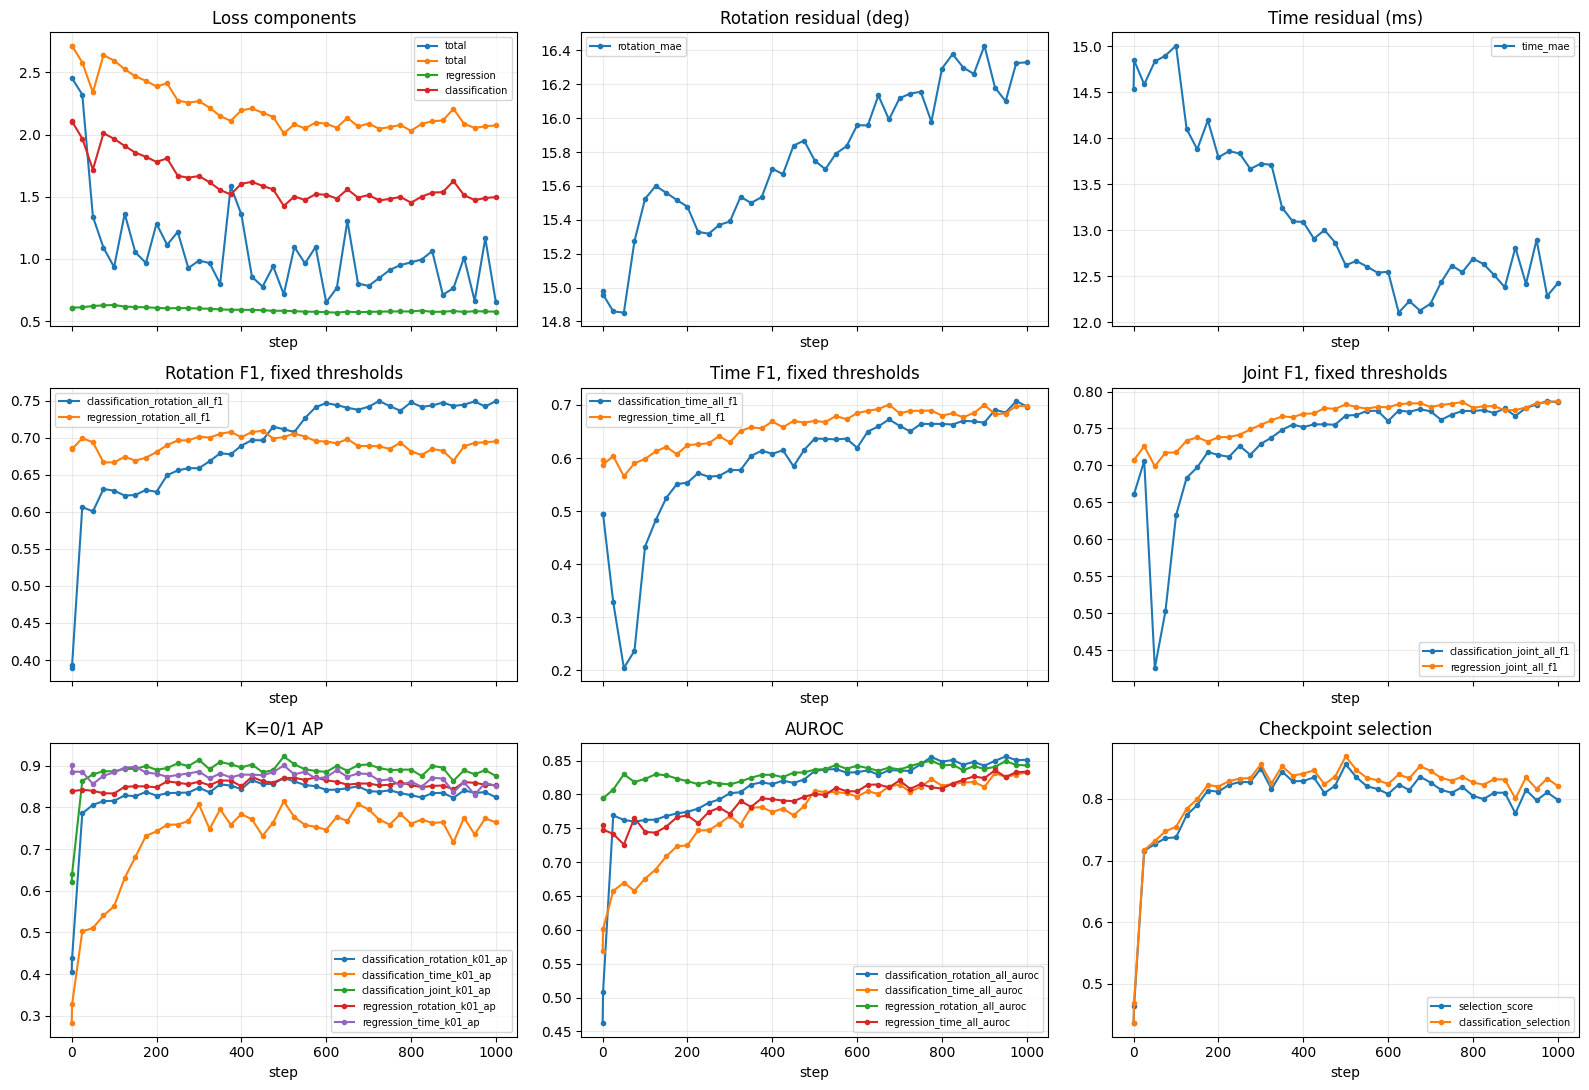

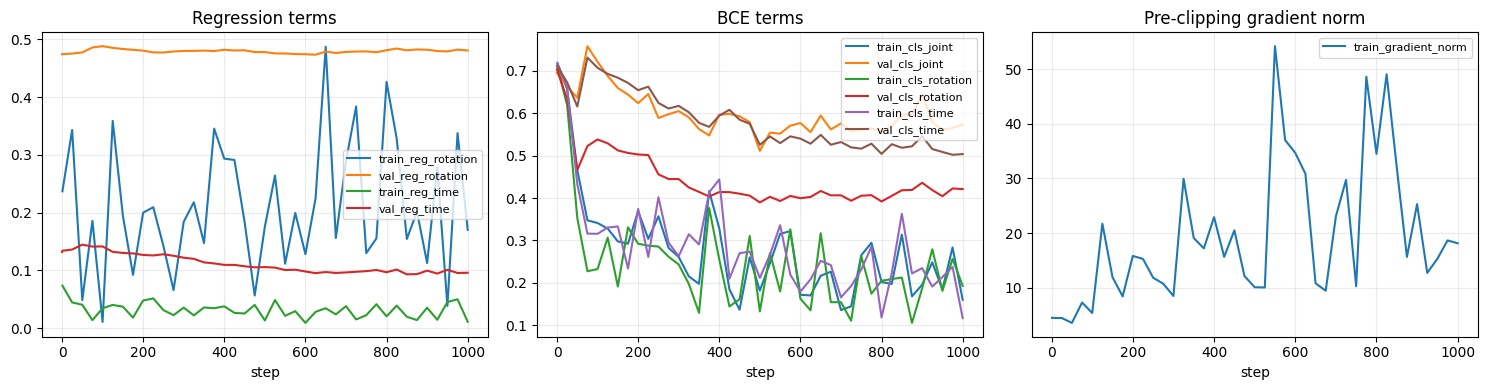

Restored complete pretrained regression + initial classifier state.


In [21]:

STOCHASTIC_STEPS = 1000
STOCHASTIC_PHYSICAL_WINDOWS = 32
STOCHASTIC_EVAL_WINDOWS = 32
STOCHASTIC_ASSESSMENT_WINDOWS = 64
STOCHASTIC_PRINT_EVERY = 25

stochastic_history = []
stochastic_monitor_indices = monitor_val_indices[np.linspace(0,len(monitor_val_indices)-1,min(STOCHASTIC_EVAL_WINDOWS,len(monitor_val_indices)),dtype=int)]
stochastic_assessment_indices = np.setdiff1d(detailed_val_indices, stochastic_monitor_indices)
stochastic_assessment_indices = stochastic_assessment_indices[np.linspace(0,len(stochastic_assessment_indices)-1,min(STOCHASTIC_ASSESSMENT_WINDOWS,len(stochastic_assessment_indices)),dtype=int)]
if RUN_STOCHASTIC_TEST and not RESUME_TRAINING:
    assert len(stochastic_monitor_indices) and len(stochastic_assessment_indices)
    model.load_state_dict(initial_state, strict=True)
    diagnostic_optimizer = make_optimizer(model)
    rng_pool = np.random.default_rng(RANDOM_SEED+811)
    diag_train_indices = rng_pool.choice(len(train_dataset), min(STOCHASTIC_PHYSICAL_WINDOWS,len(train_dataset)),replace=False)
    monitor_seed = VALIDATION_AUG_SEED+119
    try:
        diag_fixed, initial_losses = evaluate_cases(model,val_dataset,stochastic_monitor_indices,split_seed=monitor_seed)
        diag_baseline = regression_summary(diag_fixed)
        initial_metrics = summarize_monitor(diag_fixed,initial_losses,diag_baseline)
        stochastic_history.append(history_row('step',0,{},initial_metrics))
        print_monitor('Initial',initial_metrics)
        best = -np.inf
        for step in range(1,STOCHASTIC_STEPS+1):
            rng = np.random.default_rng(RANDOM_SEED+777_000+step)
            chosen = rng.choice(diag_train_indices, min(PHYSICAL_WINDOWS_PER_UPDATE,len(diag_train_indices)),replace=False)
            raw = window_batch_to(collate_windows([train_dataset[int(i)] for i in chosen]), DEVICE, dtype=MODEL_DTYPE)
            physical = fixed_seeded_physical(raw, TRAIN_AUG_SEED+step*7)
            cases = sample_fault_cases(len(chosen),rng)
            train = train_case_batch(model,diagnostic_optimizer,physical,cases)
            del raw,physical,cases
            if step==1 or step%STOCHASTIC_PRINT_EVERY==0 or step==STOCHASTIC_STEPS:
                diag_eval, losses = evaluate_cases(model,val_dataset,stochastic_monitor_indices,split_seed=monitor_seed)
                metrics = summarize_monitor(diag_eval,losses,diag_baseline)
                stochastic_history.append(history_row('step',step,train,metrics))
                print_monitor(f'Step {step}/{STOCHASTIC_STEPS} train={train["total"]:.4f}',metrics)
                if np.isfinite(metrics['selection_score']) and metrics['selection_score']>best:
                    best=metrics['selection_score']
                    save_joint_checkpoint(STOCHASTIC_BEST_PATH,model,diagnostic_optimizer,None,step,metrics)
                pd.DataFrame(stochastic_history).to_csv(RUN_DIR/'stochastic_history.csv',index=False)
        save_joint_checkpoint(STOCHASTIC_FINAL_PATH,model,diagnostic_optimizer,None,STOCHASTIC_STEPS,metrics)
    finally:
        model.load_state_dict(initial_state,strict=True)
        model.zero_grad(set_to_none=True)
        del diagnostic_optimizer
        clear_cuda()
    plot_history(stochastic_history,'step','stochastic_learning_curves.png')
    print('Restored complete pretrained regression + initial classifier state.')
else:
    print('Stochastic training skipped.')

## 12. Validation-only threshold selection and detailed reports

Tune thresholds independently for each method and checkpoint on K=0/1 validation cases. Keep them fixed on the independent stochastic assessment or final test. The same score tables also report fixed operational correction thresholds and probability 0.5, so changes in decision calibration cannot hide regression deterioration. The regression joint rule is OR of independently selected rotation and time thresholds; the classifier uses its learned joint logit. Thresholds are global per head, not sensor-specific.

In [22]:
def fit_thresholds(df):
    part = df[df.fault_count.isin((0,1))]
    thresholds = default_thresholds()
    for task in TASKS:
        y = part[f'target_{task}'].to_numpy(bool)
        if not (y.any() and (~y).any()): raise ValueError(f'No positive/negative validation examples for {task}')
        p = part[f'prob_{task}'].to_numpy(float)
        def objective(scores, threshold, inclusive):
            a = scores >= threshold if inclusive else scores > threshold
            m = classification_counts(y,a)
            # Tie-break by specificity, then higher threshold.
            return (np.nan_to_num(m['f1'],nan=-1.), np.nan_to_num(m['specificity'],nan=-1.), threshold)
        thresholds['classification'][task] = float(max(PROBABILITY_THRESHOLDS,key=lambda t:objective(p,t,True)))
        if task != 'joint':
            field, candidates = ('predicted_rotation_deg', REG_ROT_THRESHOLDS_DEG) if task=='rotation' else ('predicted_abs_tau_ms',REG_TIME_THRESHOLDS_MS)
            thresholds['regression'][task] = float(max(candidates,key=lambda t:objective(part[field].to_numpy(float),t,False)))
    return thresholds


def detailed_reports(df, label, thresholds, *, include_classification=True):
    detection_rows, residual_rows = [], []
    groups = [('all','all',df)]
    groups += [('K',str(k),df[df.fault_count==k]) for k in FAULT_COUNTS]
    groups += [('sensor',s,df[df.sensor==s]) for s in CALIBRATION_KEYS]
    groups += [('K_sensor',f'{k}|{s}',df[(df.fault_count==k)&(df.sensor==s)]) for k in FAULT_COUNTS for s in CALIBRATION_KEYS]
    groups += [('mode',mode,df[df.fault_mode==mode]) for mode in ('none',*FAULT_MODES)]
    for group,value,part in groups:
        if part.empty: continue
        residual_rows.append(dict(checkpoint=label, group=group, value=value, n=len(part), **regression_summary(part)))
        for decision,t in (('fixed',default_thresholds()),('validation_tuned',thresholds)):
            for method in (('regression','classification') if include_classification else ('regression',)):
                for task in TASKS:
                    score,alarm = score_and_alarm(part,method,task,t)
                    y = part[f'target_{task}'].to_numpy(bool)
                    m = metrics_for_scores(y,score,alarm)
                    cases = pd.DataFrame({'case_id':part.case_id,'correct':y==alarm}).groupby('case_id').correct.all()
                    detection_rows.append(dict(checkpoint=label,decision=decision,method=method,task=task,group=group,value=value,exact_case_accuracy=cases.mean() if group not in ('sensor','K_sensor') else np.nan,**m))
    return pd.DataFrame(detection_rows),pd.DataFrame(residual_rows)


def assess_checkpoints(paths, calibration_indices, assessment_dataset, assessment_indices, *, calibration_seed, assessment_seed, output_prefix, include_initial_classification=False):
    # Reuse one temporary model; do not mutate the model that is being trained.
    probe = make_initial_model()
    detection, regression, selected = [], [], {}
    for label,path in paths.items():
        if path is None:
            probe.load_state_dict(initial_state,strict=True)
        else:
            state = load_joint_checkpoint(path,probe)
            print(f'{label}: checkpoint step/epoch {state["step"]}')
            del state
        calibration_df, _ = evaluate_cases(probe,val_dataset,calibration_indices,split_seed=calibration_seed)
        thresholds = fit_thresholds(calibration_df)
        selected[label] = thresholds
        calibration_df.to_csv(RUN_DIR/f'{output_prefix}_{label}_threshold_calibration.csv',index=False)
        if assessment_dataset is val_dataset and calibration_seed == assessment_seed and np.array_equal(calibration_indices, assessment_indices):
            assessment_df = calibration_df
        else:
            assessment_df, _ = evaluate_cases(probe,assessment_dataset,assessment_indices,split_seed=assessment_seed)
        assessment_df.to_csv(RUN_DIR/f'{output_prefix}_{label}_scores.csv',index=False)
        det,reg = detailed_reports(assessment_df,label,thresholds,include_classification=(path is not None or include_initial_classification))
        detection.append(det); regression.append(reg)
        print(label,'thresholds:',thresholds,'| regression:',regression_summary(assessment_df))
        del calibration_df,assessment_df
    del probe
    clear_cuda()
    det,reg = pd.concat(detection,ignore_index=True),pd.concat(regression,ignore_index=True)
    det.to_csv(RUN_DIR/f'{output_prefix}_detection.csv',index=False)
    reg.to_csv(RUN_DIR/f'{output_prefix}_regression.csv',index=False)
    (RUN_DIR/f'{output_prefix}_thresholds.json').write_text(json.dumps(selected,indent=2))
    display(reg[(reg.group=='all')|((reg.group=='K')&reg.value.isin(['0','1']))].round(3))
    display(det[(det.decision=='validation_tuned')&((det.group=='all')|((det.group=='K')&det.value.isin(['0','1'])))][['checkpoint','method','task','group','value','precision','recall','f1','ap','auroc','false_positive_rate','exact_case_accuracy']].round(3))
    print('Clean per-sensor false alarms (K=0):')
    display(det[(det.decision=='validation_tuned')&(det.group=='K_sensor')&det.value.str.startswith('0|')][['checkpoint','method','task','value','false_positive_rate','fp','tn']].round(3))
    return det,reg,selected

## 13. Independent stochastic checkpoint assessment

The monitor curves in Section 11 show learning through time. This second evaluation uses unseen validation windows for initial/best/final and compares both regression and classification. Initial classifier scores are deliberately included here as a random-head baseline, not as a trained method.

In [23]:
if RUN_STOCHASTIC_CHECKPOINT_EVALUATION and not RESUME_TRAINING:
    stochastic_paths = {'initial':None,'stochastic_best':STOCHASTIC_BEST_PATH,'stochastic_final':STOCHASTIC_FINAL_PATH}
    if not all(path is None or path.is_file() for path in stochastic_paths.values()):
        raise FileNotFoundError('Run stochastic preflight first, or disable RUN_STOCHASTIC_CHECKPOINT_EVALUATION.')
    stochastic_detection,stochastic_regression,stochastic_thresholds = assess_checkpoints(stochastic_paths,stochastic_monitor_indices,val_dataset,stochastic_assessment_indices,calibration_seed=VALIDATION_AUG_SEED+119,assessment_seed=VALIDATION_AUG_SEED+431,output_prefix='stochastic_assessment',include_initial_classification=True)

initial thresholds: {'classification': {'joint': 0.51, 'rotation': 0.51, 'time': 0.52}, 'regression': {'rotation': 3.0, 'time': 30.0}} | regression: {'rotation_mae': 12.804896901726412, 'time_mae': 14.04017549387645, 'rotation_p90': 30.746328544616865, 'time_p90': 38.85931968688967}
stochastic_best: checkpoint step/epoch 500
stochastic_best thresholds: {'classification': {'joint': 0.76, 'rotation': 0.36, 'time': 0.5700000000000001}, 'regression': {'rotation': 5.0, 'time': 20.0}} | regression: {'rotation_mae': 13.268345864803996, 'time_mae': 11.748919735835322, 'rotation_p90': 34.88637275695803, 'time_p90': 35.758130645751955}
stochastic_final: checkpoint step/epoch 1000
stochastic_final thresholds: {'classification': {'joint': 0.96, 'rotation': 0.72, 'time': 0.56}, 'regression': {'rotation': 7.5, 'time': 30.0}} | regression: {'rotation_mae': 14.005115906985399, 'time_mae': 11.523142312806643, 'rotation_p90': 34.92309722900397, 'time_p90': 33.15818176269532}


,checkpoint,group,value,n,rotation_mae,time_mae,rotation_p90,time_p90
0,initial,all,all,1920,12.805,14.040,30.746,38.859
1,initial,K,0,192,1.206,6.139,2.610,17.389
2,initial,K,1,576,8.167,5.951,7.841,19.304
24,stochastic_best,all,all,1920,13.268,11.749,34.886,35.758
25,stochastic_best,K,0,192,0.722,3.114,1.536,8.683
26,stochastic_best,K,1,576,8.693,5.209,12.229,17.861
48,stochastic_final,all,all,1920,14.005,11.523,34.923,33.158
49,stochastic_final,K,0,192,2.005,6.698,4.032,22.269
50,stochastic_final,K,1,576,9.419,6.681,15.225,22.605


,checkpoint,method,task,group,value,precision,recall,f1,ap,auroc,false_positive_rate,exact_case_accuracy
6,initial,regression,joint,all,all,0.913,0.556,0.691,0.820,0.754,0.053,0.425
7,initial,regression,rotation,all,all,0.746,0.582,0.654,0.723,0.736,0.082,0.552
8,initial,regression,time,all,all,0.896,0.488,0.632,0.731,0.751,0.028,0.566
9,initial,classification,joint,all,all,0.498,1.000,0.665,0.627,0.513,1.000,0.164
10,initial,classification,rotation,all,all,0.265,0.373,0.310,0.424,0.432,0.426,0.147
11,initial,classification,time,all,all,0.329,0.984,0.493,0.430,0.609,0.986,0.102
18,initial,regression,joint,K,0,0.000,NaN,0.000,NaN,NaN,0.089,0.750
19,initial,regression,rotation,K,0,0.000,NaN,0.000,NaN,NaN,0.078,0.781
20,initial,regression,time,K,0,0.000,NaN,0.000,NaN,NaN,0.016,0.953
21,initial,classification,joint,K,0,0.000,NaN,0.000,NaN,NaN,1.000,0.000


Clean per-sensor false alarms (K=0):


,checkpoint,method,task,value,false_positive_rate,fp,tn
102,initial,regression,joint,0|imu,0.109,7,57
103,initial,regression,rotation,0|imu,0.109,7,57
104,initial,regression,time,0|imu,0.000,0,64
105,initial,classification,joint,0|imu,1.000,64,0
106,initial,classification,rotation,0|imu,0.328,21,43
107,initial,classification,time,0|imu,1.000,64,0
114,initial,regression,joint,0|lidar,0.078,5,59
115,initial,regression,rotation,0|lidar,0.047,3,61
116,initial,regression,time,0|lidar,0.031,2,62
117,initial,classification,joint,0|lidar,1.000,64,0


## 14. Full fine-tuning (independent of stochastic training)

In [ ]:
clear_cuda()

Pretrained initial | val total=2.5943 reg=0.4852 cls=2.1091 | residual R=12.27° tau=14.45ms | cls F1 J=0.664 R=0.388 T=0.502 | cls AP J=0.647 R=0.400 T=0.416 | reg F1 R=0.665 T=0.605 | selection=0.4143

Epoch 1/100
Epoch 1 train=1.4025 | val total=2.1954 reg=0.4783 cls=1.7170 | residual R=12.59° tau=13.08ms | cls F1 J=0.707 R=0.653 T=0.557 | cls AP J=0.843 R=0.726 T=0.683 | reg F1 R=0.662 T=0.648 | selection=0.8474
Train K fractions: [0.05, 0.85, 0.047, 0.052] | regression relative MAE: 1.025 0.905
Saved best.pt
Saved best_classification.pt
Saved best_regression.pt

Epoch 2/100
Epoch 2 train=1.0223 | val total=1.9039 reg=0.4512 cls=1.4527 | residual R=12.54° tau=11.80ms | cls F1 J=0.741 R=0.696 T=0.600 | cls AP J=0.887 R=0.773 T=0.766 | reg F1 R=0.679 T=0.695 | selection=0.8909
Train K fractions: [0.05, 0.845, 0.051, 0.053] | regression relative MAE: 1.022 0.817
Saved best.pt
Saved best_classification.pt
Saved best_regression.pt

Epoch 3/100
Epoch 3 train=0.9708 | val total=1.7402 reg=

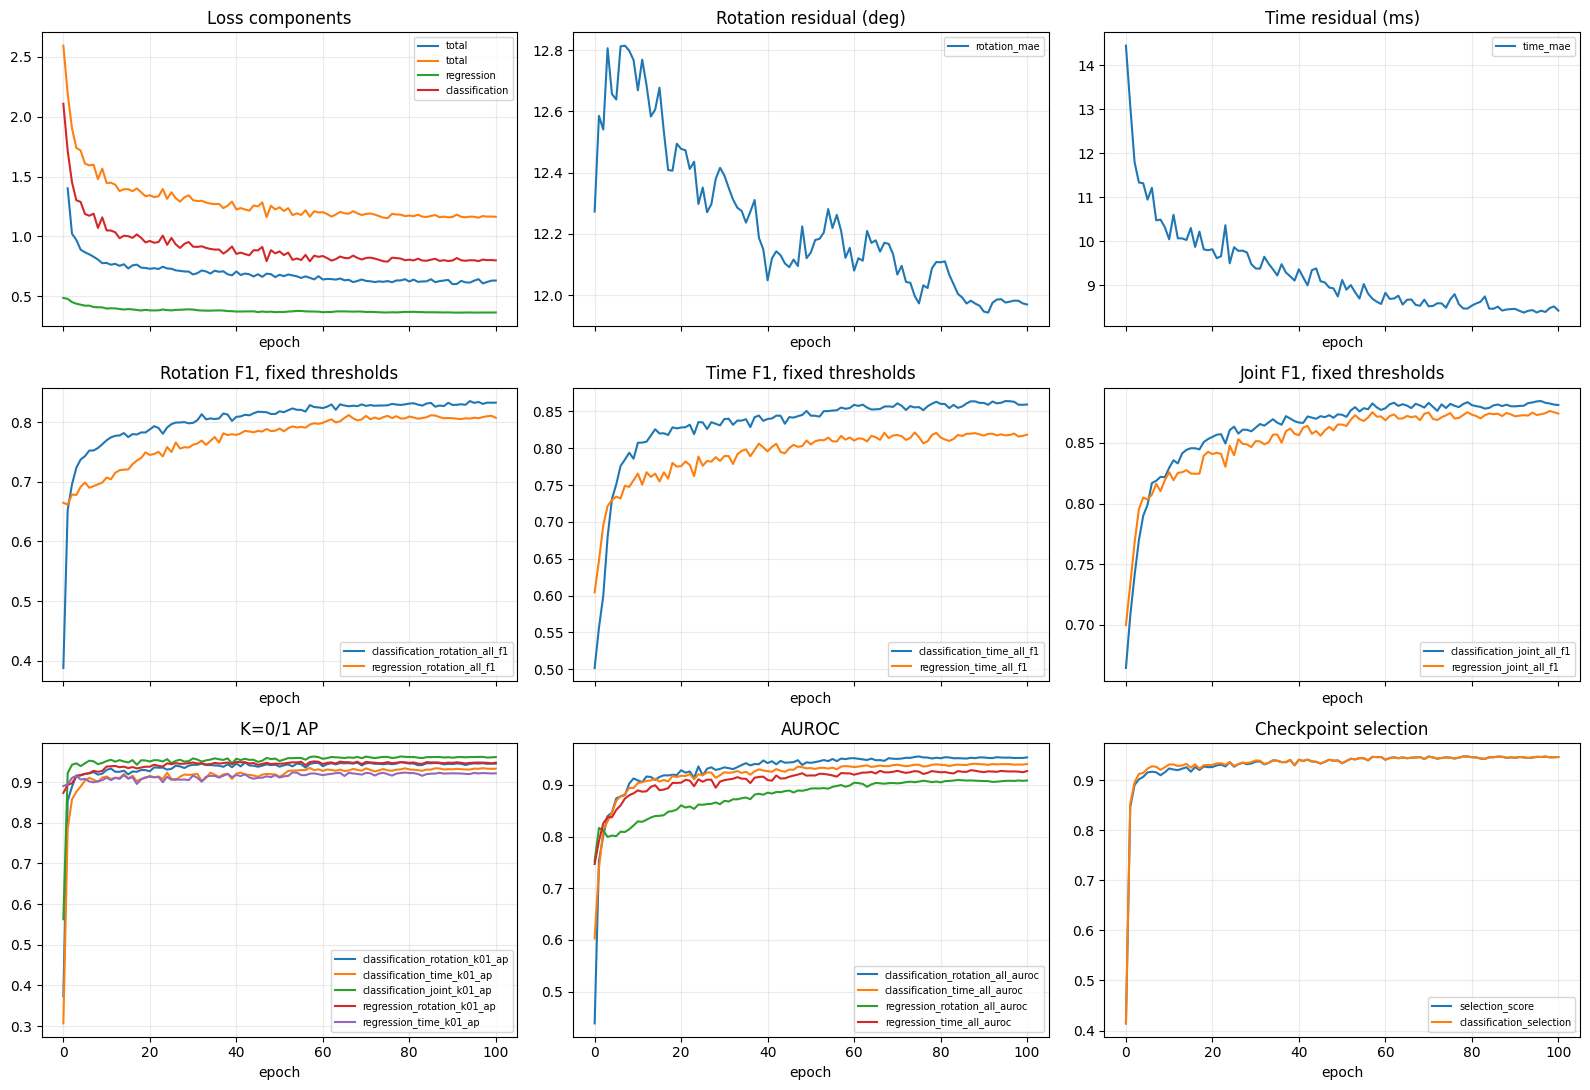

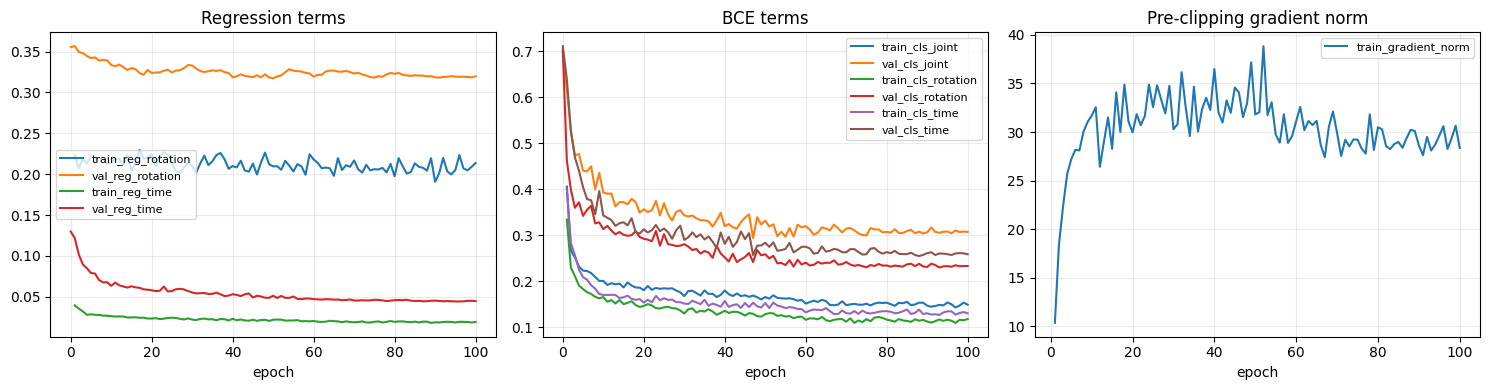

In [26]:
training_history = []
if RUN_FULL_TRAINING:
    model.load_state_dict(initial_state,strict=True)
    optimizer = make_optimizer(model)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='min',factor=LR_REDUCTION_FACTOR,patience=LR_PATIENCE_EPOCHS)
    monitor_seed = VALIDATION_AUG_SEED
    reference_df,reference_losses = evaluate_cases(model,val_dataset,monitor_val_indices,split_seed=monitor_seed)
    full_baseline = regression_summary(reference_df)
    initial_metrics = summarize_monitor(reference_df,reference_losses,full_baseline)
    print_monitor('Pretrained initial',initial_metrics)
    del reference_df
    start_epoch,global_step = 0,0
    best_scores = {'selection_score':-np.inf,'classification_selection':-np.inf,'regression_selection':-np.inf}
    if RESUME_TRAINING:
        state = load_joint_checkpoint(LAST_CHECKPOINT_PATH,model)
        optimizer.load_state_dict(state['optimizer_state_dict'])
        scheduler.load_state_dict(state['scheduler_state_dict'])
        start_epoch,global_step = int(state['step']),int(state['global_step'])
        best_scores = state['best_scores']
        train_shuffle_generator.set_state(state['train_shuffle_state'])
        torch.set_rng_state(state['torch_rng_state'])
        if DEVICE.type=='cuda' and state['cuda_rng_state']: torch.cuda.set_rng_state_all(state['cuda_rng_state'])
        history_path = RUN_DIR/'training_history.csv'
        if history_path.is_file(): training_history = pd.read_csv(history_path).query('epoch <= @start_epoch').to_dict('records')
        del state
    else:
        if any(path.exists() for path in (BEST_CHECKPOINT_PATH,BEST_CLASSIFICATION_PATH,BEST_REGRESSION_PATH,LAST_CHECKPOINT_PATH)):
            raise FileExistsError('Full-training checkpoints already exist. Change RUN_NAME or resume.')
        training_history.append(history_row('epoch',0,{},initial_metrics))
        # Ensure independent, deterministic full-training shuffle/initial random streams.
        train_shuffle_generator.manual_seed(RANDOM_SEED+25)
        torch.manual_seed(RANDOM_SEED+89)
        if DEVICE.type=='cuda': torch.cuda.manual_seed_all(RANDOM_SEED+89)
    for epoch in range(start_epoch,NUM_EPOCHS):
        print(f'\nEpoch {epoch+1}/{NUM_EPOCHS}')
        train,global_step = run_train_epoch(model,optimizer,epoch,global_step)
        monitor_df,losses = evaluate_cases(model,val_dataset,monitor_val_indices,split_seed=monitor_seed)
        val = summarize_monitor(monitor_df,losses,full_baseline)
        del monitor_df
        scheduler.step(val['total'])
        row = history_row('epoch',epoch+1,train,val)
        row.update(global_step=global_step,**{f'lr_{g["name"]}':g['lr'] for g in optimizer.param_groups})
        training_history.append(row)
        print_monitor(f'Epoch {epoch+1} train={train["total"]:.4f}',val)
        # print('Train K fractions:',[round(train[f'k{k}_fraction'],3) for k in range(4)],'| regression relative MAE:',round(val['rotation_ratio'],3),round(val['time_ratio'],3))
        checkpoints = {'selection_score':BEST_CHECKPOINT_PATH,'classification_selection':BEST_CLASSIFICATION_PATH,'regression_selection':BEST_REGRESSION_PATH}
        improved = [k for k in checkpoints if np.isfinite(val[k]) and val[k]>best_scores[k]]
        for k in improved: best_scores[k]=float(val[k])
        for k in improved:
            save_joint_checkpoint(checkpoints[k],model,optimizer,scheduler,epoch+1,val,best_scores,global_step)
            print('Saved',checkpoints[k].name)
        save_joint_checkpoint(LAST_CHECKPOINT_PATH,model,optimizer,scheduler,epoch+1,val,best_scores,global_step)
        pd.DataFrame(training_history).to_csv(RUN_DIR/'training_history.csv',index=False)
        clear_cuda()
    plot_history(training_history,'epoch','full_training_learning_curves.png')
else:
    print('Full training disabled; existing checkpoints may still be evaluated.')

## 15. Full-model validation and untouched test reports

Evaluate all four trained checkpoints against frozen 002.27 on identical cases. Save raw per-sensor outputs and thresholds, and report both correction residuals and detection quality. On test, calibration thresholds are fitted only using detailed validation; never tune on test. Validation performance after threshold selection is descriptive, not an independent estimate.

In [27]:
full_paths = {'002.27':None,'best':BEST_CHECKPOINT_PATH,'best_classification':BEST_CLASSIFICATION_PATH,'best_regression':BEST_REGRESSION_PATH,'last':LAST_CHECKPOINT_PATH}
if RUN_DETAILED_EVALUATION or RUN_TEST_EVALUATION:
    for name,path in full_paths.items():
        if path is not None and not path.is_file(): raise FileNotFoundError(f'Missing {name}: {path}')
if RUN_DETAILED_EVALUATION:
    full_validation_detection,full_validation_regression,validation_thresholds = assess_checkpoints(full_paths,detailed_val_indices,val_dataset,detailed_val_indices,calibration_seed=VALIDATION_AUG_SEED+331,assessment_seed=VALIDATION_AUG_SEED+331,output_prefix='full_validation')
if RUN_TEST_EVALUATION:
    full_test_detection,full_test_regression,test_thresholds = assess_checkpoints(full_paths,detailed_val_indices,test_dataset,detailed_test_indices,calibration_seed=VALIDATION_AUG_SEED+331,assessment_seed=TEST_AUG_SEED+331,output_prefix='full_test')

002.27 thresholds: {'classification': {'joint': 0.51, 'rotation': 0.51, 'time': 0.51}, 'regression': {'rotation': 10.0, 'time': 30.0}} | regression: {'rotation_mae': 12.529816949744022, 'time_mae': 14.224645238814968, 'rotation_p90': 27.884464836120614, 'time_p90': 40.91481475830079}
best: checkpoint step/epoch 78
best thresholds: {'classification': {'joint': 0.8200000000000001, 'rotation': 0.71, 'time': 0.75}, 'regression': {'rotation': 5.0, 'time': 20.0}} | regression: {'rotation_mae': 12.378006343518713, 'time_mae': 8.552260039161617, 'rotation_p90': 33.13622436523439, 'time_p90': 22.910177803039552}
best_classification: checkpoint step/epoch 78
best_classification thresholds: {'classification': {'joint': 0.8200000000000001, 'rotation': 0.71, 'time': 0.75}, 'regression': {'rotation': 5.0, 'time': 20.0}} | regression: {'rotation_mae': 12.378006343518713, 'time_mae': 8.552260039161617, 'rotation_p90': 33.13622436523439, 'time_p90': 22.910177803039552}
best_regression: checkpoint step/

,checkpoint,group,value,n,rotation_mae,time_mae,rotation_p90,time_p90
0,002.27,all,all,10320,12.530,14.225,27.884,40.915
1,002.27,K,0,1032,1.153,6.545,2.086,16.392
2,002.27,K,1,3096,6.819,6.251,6.389,19.231
24,best,all,all,10320,12.378,8.552,33.136,22.910
25,best,K,0,1032,0.778,3.743,1.379,9.065
26,best,K,1,3096,6.730,5.160,6.492,13.469
48,best_classification,all,all,10320,12.378,8.552,33.136,22.910
49,best_classification,K,0,1032,0.778,3.743,1.379,9.065
50,best_classification,K,1,3096,6.730,5.160,6.492,13.469
72,best_regression,all,all,10320,12.316,8.494,32.785,23.263


,checkpoint,method,task,group,value,precision,recall,f1,ap,auroc,false_positive_rate,exact_case_accuracy
3,002.27,regression,joint,all,all,0.981,0.510,0.671,0.833,0.767,0.010,0.433
4,002.27,regression,rotation,all,all,0.953,0.491,0.648,0.740,0.759,0.010,0.639
5,002.27,regression,time,all,all,0.910,0.472,0.621,0.730,0.749,0.023,0.578
9,002.27,regression,joint,K,0,0.000,NaN,0.000,NaN,NaN,0.018,0.951
10,002.27,regression,rotation,K,0,0.000,NaN,0.000,NaN,NaN,0.008,0.977
...,...,...,...,...,...,...,...,...,...,...,...,...
1039,last,regression,rotation,K,1,0.947,0.799,0.867,0.947,0.985,0.008,0.887
1040,last,regression,time,K,1,0.959,0.790,0.866,0.923,0.958,0.008,0.861
1041,last,classification,joint,K,1,0.975,0.844,0.905,0.968,0.982,0.009,0.856
1042,last,classification,rotation,K,1,0.963,0.795,0.871,0.950,0.985,0.006,0.891


Clean per-sensor false alarms (K=0):


,checkpoint,method,task,value,false_positive_rate,fp,tn
51,002.27,regression,joint,0|imu,0.000,0,344
52,002.27,regression,rotation,0|imu,0.000,0,344
53,002.27,regression,time,0|imu,0.000,0,344
57,002.27,regression,joint,0|lidar,0.020,7,337
58,002.27,regression,rotation,0|lidar,0.009,3,341
...,...,...,...,...,...,...,...
1135,last,regression,rotation,0|lidar_right,0.009,3,341
1136,last,regression,time,0|lidar_right,0.009,3,341
1137,last,classification,joint,0|lidar_right,0.023,8,336
1138,last,classification,rotation,0|lidar_right,0.003,1,343


002.27 thresholds: {'classification': {'joint': 0.51, 'rotation': 0.51, 'time': 0.51}, 'regression': {'rotation': 10.0, 'time': 30.0}} | regression: {'rotation_mae': 12.634975091057395, 'time_mae': 14.228334326769907, 'rotation_p90': 27.133609199523953, 'time_p90': 40.56427955627442}
best: checkpoint step/epoch 78
best thresholds: {'classification': {'joint': 0.8200000000000001, 'rotation': 0.71, 'time': 0.75}, 'regression': {'rotation': 5.0, 'time': 20.0}} | regression: {'rotation_mae': 12.218372621856444, 'time_mae': 8.4390532339445, 'rotation_p90': 32.26150665283206, 'time_p90': 23.097232246398935}
best_classification: checkpoint step/epoch 78
best_classification thresholds: {'classification': {'joint': 0.8200000000000001, 'rotation': 0.71, 'time': 0.75}, 'regression': {'rotation': 5.0, 'time': 20.0}} | regression: {'rotation_mae': 12.218372621856444, 'time_mae': 8.4390532339445, 'rotation_p90': 32.26150665283206, 'time_p90': 23.097232246398935}
best_regression: checkpoint step/epoc

,checkpoint,group,value,n,rotation_mae,time_mae,rotation_p90,time_p90
0,002.27,all,all,15000,12.635,14.228,27.134,40.564
1,002.27,K,0,1500,1.009,6.412,2.056,16.886
2,002.27,K,1,4500,6.877,5.802,6.371,18.354
24,best,all,all,15000,12.218,8.439,32.262,23.097
25,best,K,0,1500,0.686,3.646,1.308,8.871
26,best,K,1,4500,7.068,5.064,6.711,13.271
48,best_classification,all,all,15000,12.218,8.439,32.262,23.097
49,best_classification,K,0,1500,0.686,3.646,1.308,8.871
50,best_classification,K,1,4500,7.068,5.064,6.711,13.271
72,best_regression,all,all,15000,12.178,8.362,32.473,23.207


,checkpoint,method,task,group,value,precision,recall,f1,ap,auroc,false_positive_rate,exact_case_accuracy
3,002.27,regression,joint,all,all,0.985,0.507,0.669,0.834,0.768,0.008,0.444
4,002.27,regression,rotation,all,all,0.965,0.481,0.642,0.744,0.759,0.007,0.640
5,002.27,regression,time,all,all,0.915,0.474,0.624,0.734,0.752,0.022,0.585
9,002.27,regression,joint,K,0,0.000,NaN,0.000,NaN,NaN,0.015,0.958
10,002.27,regression,rotation,K,0,0.000,NaN,0.000,NaN,NaN,0.007,0.978
...,...,...,...,...,...,...,...,...,...,...,...,...
1039,last,regression,rotation,K,1,0.973,0.812,0.886,0.967,0.989,0.004,0.899
1040,last,regression,time,K,1,0.962,0.808,0.879,0.927,0.959,0.007,0.875
1041,last,classification,joint,K,1,0.983,0.854,0.914,0.971,0.983,0.006,0.869
1042,last,classification,rotation,K,1,0.987,0.814,0.892,0.966,0.988,0.002,0.905


Clean per-sensor false alarms (K=0):


,checkpoint,method,task,value,false_positive_rate,fp,tn
51,002.27,regression,joint,0|imu,0.004,2,498
52,002.27,regression,rotation,0|imu,0.004,2,498
53,002.27,regression,time,0|imu,0.000,0,500
57,002.27,regression,joint,0|lidar,0.014,7,493
58,002.27,regression,rotation,0|lidar,0.006,3,497
...,...,...,...,...,...,...,...
1135,last,regression,rotation,0|lidar_right,0.002,1,499
1136,last,regression,time,0|lidar_right,0.008,4,496
1137,last,classification,joint,0|lidar_right,0.014,7,493
1138,last,classification,rotation,0|lidar_right,0.000,0,500


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


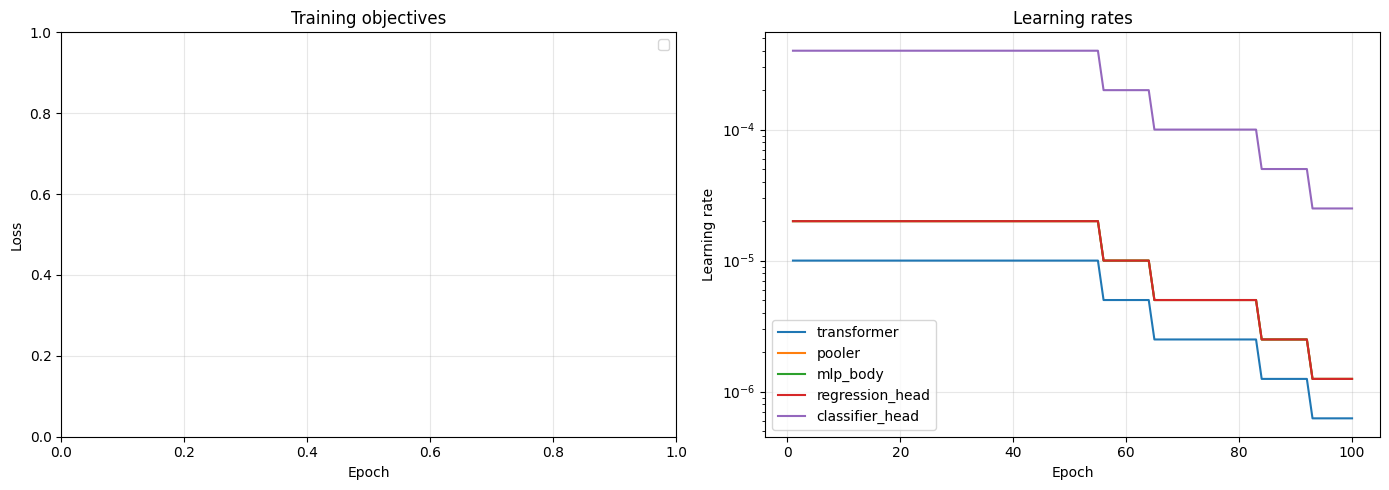

,epoch,val_total,val_regression,val_classification,val_reg_rotation,val_reg_time,val_cls_joint,val_cls_rotation,val_cls_time,val_rotation_mae,...,train_k0_fraction,train_k1_fraction,train_k2_fraction,train_k3_fraction,global_step,lr_transformer,lr_pooler,lr_mlp_body,lr_regression_head,lr_classifier_head
96,96,1.15692,0.36326,0.79366,0.31909,0.04417,0.30445,0.23186,0.25734,11.97886,...,0.04511,0.84621,0.05234,0.05633,24096.0,0.0,0.0,0.0,0.0,0.00002
97,97,1.16996,0.36368,0.80628,0.31929,0.04438,0.31046,0.23502,0.26079,11.98234,...,0.05097,0.85132,0.05160,0.04611,24347.0,0.0,0.0,0.0,0.0,0.00002
98,98,1.16552,0.36387,0.80165,0.31896,0.04491,0.30722,0.23302,0.26141,11.98188,...,0.05508,0.84222,0.04848,0.05421,24598.0,0.0,0.0,0.0,0.0,0.00002
99,99,1.16614,0.36351,0.80263,0.31849,0.04502,0.30817,0.23351,0.26095,11.97323,...,0.05471,0.84746,0.05247,0.04536,24849.0,0.0,0.0,0.0,0.0,0.00002
100,100,1.16395,0.36434,0.79960,0.31974,0.04460,0.30740,0.23337,0.25884,11.96974,...,0.04948,0.85182,0.05085,0.04786,25100.0,0.0,0.0,0.0,0.0,0.00002


In [29]:
import pandas as pd
import matplotlib.pyplot as plt

# Use in-memory history, or recover it from the session CSV.
if 'training_history' in globals() and len(training_history):
    hist = pd.DataFrame(training_history)
else:
    hist = pd.read_csv(RUN_DIR / 'training_history_session.csv')

hist = hist.sort_values('epoch')
x = hist['epoch'] if 'epoch' in hist else hist['global_step']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Learning objectives
objective_pairs = [
    ('Total', 'train_loss_total', ['val_loss_total', 'val_loss']),
    ('Regression', 'train_loss_reg', ['val_loss_reg', 'val_reg_loss']),
    ('Classification', 'train_loss_cls', ['val_loss_cls', 'val_cls_loss']),
]

for name, train_col, val_candidates in objective_pairs:
    if train_col not in hist:
        continue

    axes[0].plot(x, hist[train_col], label=f'{name} train')
    val_col = next((c for c in val_candidates if c in hist), None)
    if val_col:
        axes[0].plot(x, hist[val_col], '--', label=f'{name} val')

axes[0].set(title='Training objectives', xlabel='Epoch', ylabel='Loss')
axes[0].grid(alpha=0.3)
axes[0].legend()

# Learning rates
lr_cols = [c for c in hist.columns if c.startswith('lr_')]
for col in lr_cols:
    axes[1].plot(x, hist[col], label=col.removeprefix('lr_'))

axes[1].set(title='Learning rates', xlabel='Epoch', ylabel='Learning rate')
axes[1].set_yscale('log')
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

display(hist.tail(5).round(5))

## 16. Matched controlled K=1 rotation sweeps

Compare original regression, hybrid regression and hybrid classifier on the same cases. Sweep uses test windows when final test is enabled, otherwise validation for diagnosis. Use **fixed operational regression thresholds** and the **validation-selected classifier thresholds** for the primary plot; a second plot uses validation-tuned thresholds for both approaches. Residuals are computed from the actual left update, not correction magnitude. Angles at/below tolerance have no positives, so their F1 is omitted.

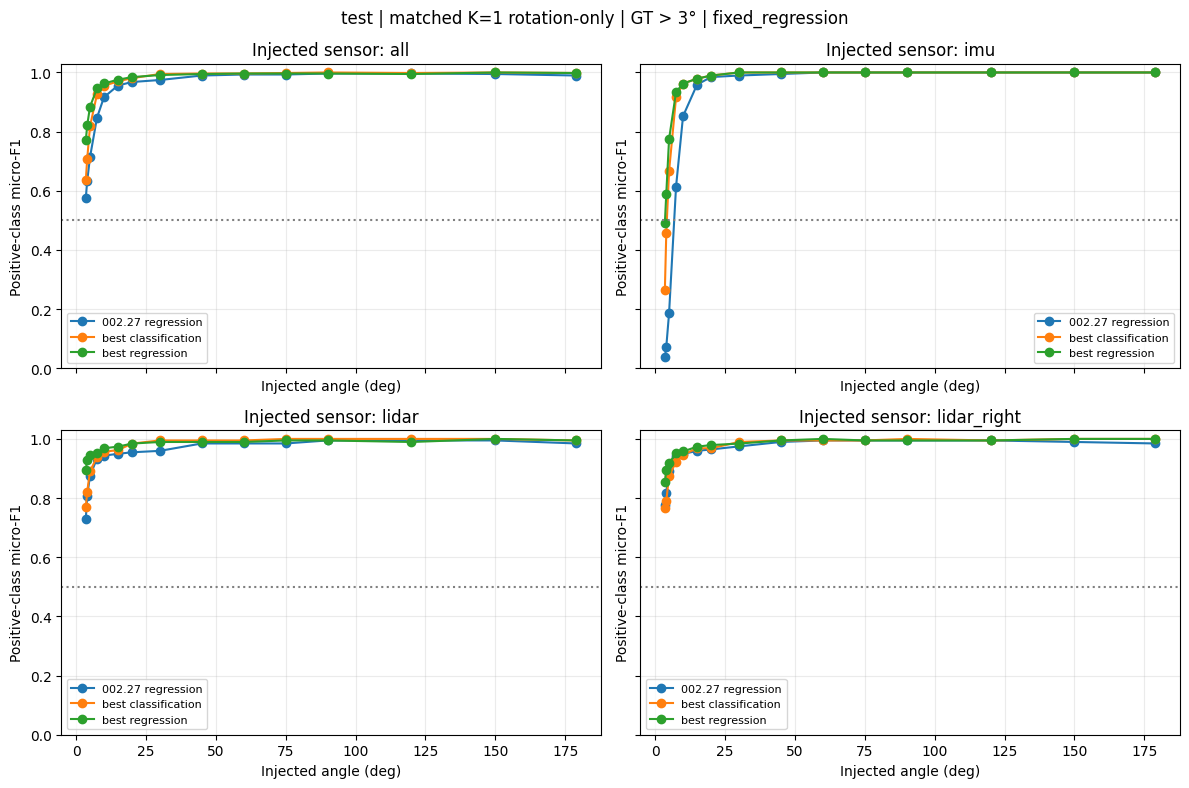

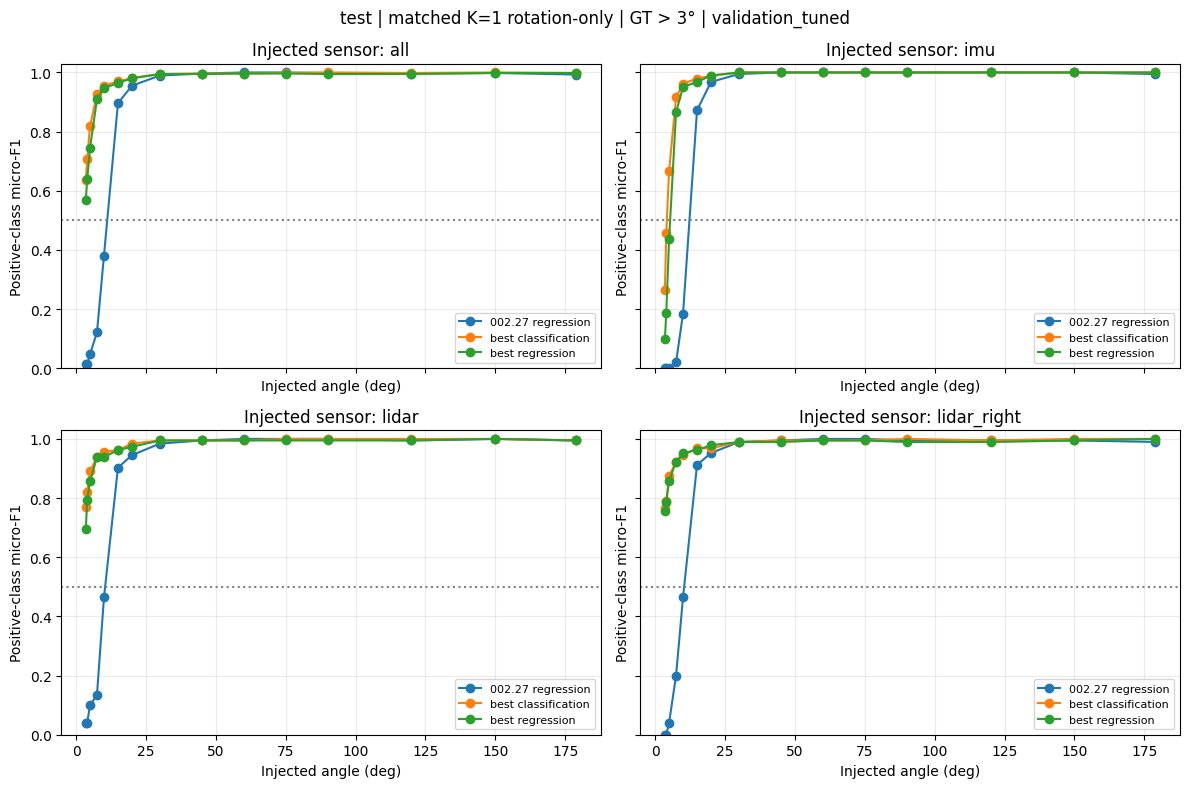

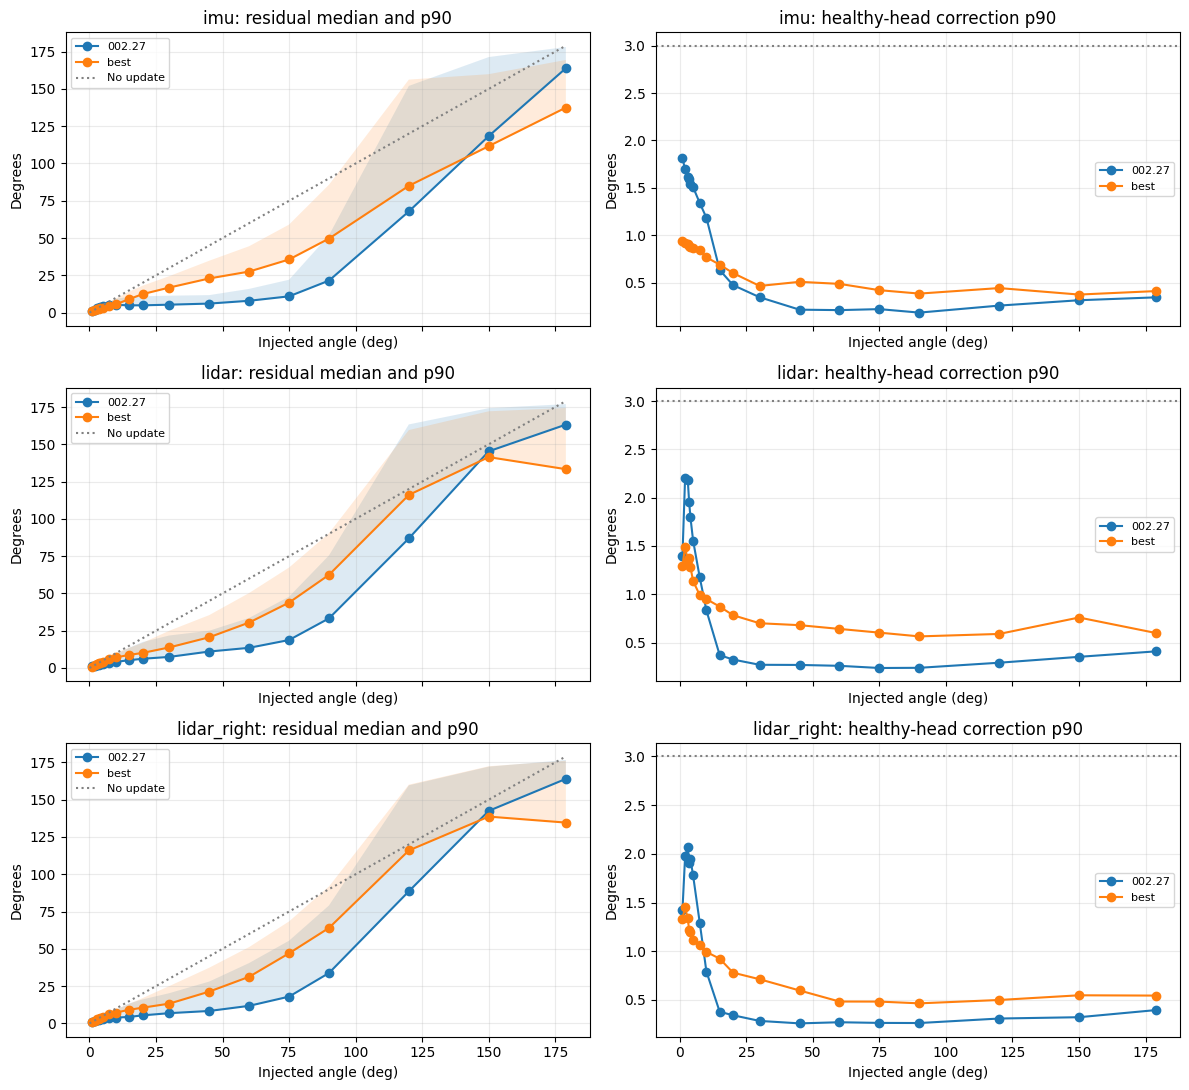

In [30]:
def sweep_metrics(df,label,thresholds,include_classifier):
    rows=[]
    for sensor in ('all',*CALIBRATION_KEYS):
        data=df if sensor=='all' else df[df.selected_sensor==sensor]
        for angle,part in data.groupby('angle_deg'):
            selected=part[part.sensor==part.selected_sensor]
            healthy=part[part.sensor!=part.selected_sensor]
            y=part.target_rotation.to_numpy(bool)
            if not len(selected): continue
            for method in (('regression','classification') if include_classifier else ('regression',)):
                for decision in ('fixed_regression','validation_tuned'):
                    t=default_thresholds() if decision=='fixed_regression' and method=='regression' else thresholds
                    score,alarm=score_and_alarm(part,method,'rotation',t)
                    m=metrics_for_scores(y,score,alarm)
                    exact=pd.DataFrame(dict(case=part.case_id,correct=y==alarm)).groupby('case').correct.all().mean()
                    rows.append(dict(checkpoint=label,method=method,decision=decision,sensor=sensor,angle_deg=angle,n_cases=part.case_id.nunique(),f1=m['f1'] if y.any() else np.nan,recall=m['recall'],precision=m['precision'],exact=exact,selected_residual_median=selected.residual_deg.median(),selected_residual_p90=selected.residual_deg.quantile(.9),healthy_correction_p90=healthy.predicted_rotation_deg.quantile(.9)))
    return pd.DataFrame(rows)


if RUN_CONTROLLED_SWEEP:
    if not BEST_CHECKPOINT_PATH.is_file(): raise FileNotFoundError(BEST_CHECKPOINT_PATH)
    sweep_dataset,sweep_names,sweep_split=(test_dataset,TEST_NAMES,'test') if RUN_TEST_EVALUATION else (val_dataset,VAL_NAMES,'validation')
    sweep_indices=select_spread_indices_by_names(sweep_dataset,sweep_names,SWEEP_WINDOWS_PER_SEQUENCE,RANDOM_SEED+900)
    sweep_seed=(TEST_AUG_SEED if RUN_TEST_EVALUATION else VALIDATION_AUG_SEED)+900
    thresholds_path=RUN_DIR/('full_test_thresholds.json' if RUN_TEST_EVALUATION else 'full_validation_thresholds.json')
    if not thresholds_path.is_file(): raise FileNotFoundError('Run detailed validation/test evaluation before sweep to obtain validation-selected thresholds.')
    thresholds=json.loads(thresholds_path.read_text())
    probe=make_initial_model()
    sweep_reports=[]
    for label,path in {'002.27':None,'best':BEST_CHECKPOINT_PATH}.items():
        if path is None: probe.load_state_dict(initial_state,strict=True)
        else: load_joint_checkpoint(path,probe)
        df,_=evaluate_cases(probe,sweep_dataset,sweep_indices,split_seed=sweep_seed,controlled=True)
        df.to_csv(RUN_DIR/f'{sweep_split}_controlled_{label}_scores.csv',index=False)
        sweep_reports.append(sweep_metrics(df,label,thresholds[label],path is not None))
        del df
    del probe
    clear_cuda()
    sweep_df=pd.concat(sweep_reports,ignore_index=True)
    sweep_df.to_csv(RUN_DIR/f'{sweep_split}_controlled_summary.csv',index=False)
    for decision in ('fixed_regression','validation_tuned'):
        fig,axes=plt.subplots(2,2,figsize=(12,8),sharex=True,sharey=True)
        for ax,sensor in zip(axes.flat,('all',*CALIBRATION_KEYS)):
            part=sweep_df[(sweep_df.sensor==sensor)&(sweep_df.decision==decision)]
            for (checkpoint,method),g in part.groupby(['checkpoint','method']):
                ax.plot(g.angle_deg,g.f1,'-o',label=f'{checkpoint} {method}')
            ax.axhline(.5,color='gray',linestyle=':'); ax.set(title=f'Injected sensor: {sensor}',xlabel='Injected angle (deg)',ylabel='Positive-class micro-F1',ylim=(0,1.03)); ax.grid(alpha=.25); ax.legend(fontsize=8)
        fig.suptitle(f'{sweep_split} | matched K=1 rotation-only | GT > {GT_ROT_TOL_DEG:g}° | {decision}')
        finish_figure(fig,f'{sweep_split}_k1_f1_{decision}.png')
    fig,axes=plt.subplots(3,2,figsize=(12,11),sharex=True)
    for row,sensor in enumerate(CALIBRATION_KEYS):
        part=sweep_df[(sweep_df.sensor==sensor)&(sweep_df.method=='regression')&(sweep_df.decision=='fixed_regression')]
        for checkpoint,g in part.groupby('checkpoint'):
            x=g.angle_deg.to_numpy(float); median=g.selected_residual_median.to_numpy(float); p90=g.selected_residual_p90.to_numpy(float)
            axes[row,0].plot(x,median,'-o',label=checkpoint); axes[row,0].fill_between(x,median,p90,alpha=.15)
            axes[row,1].plot(x,g.healthy_correction_p90,'-o',label=checkpoint)
        axes[row,0].plot([0,179],[0,179],':',color='gray',label='No update')
        axes[row,1].axhline(GT_ROT_TOL_DEG,color='gray',linestyle=':')
        axes[row,0].set(title=f'{sensor}: residual median and p90',ylabel='Degrees')
        axes[row,1].set(title=f'{sensor}: healthy-head correction p90',ylabel='Degrees')
        for ax in axes[row]: ax.set_xlabel('Injected angle (deg)'); ax.grid(alpha=.25); ax.legend(fontsize=8)
    finish_figure(fig,f'{sweep_split}_k1_regression_retention.png')

## 17. Optional chronological rollout: does classification recognize unsuccessful correction?

Use actual consecutive held-out windows and a consistent re-expressed physical truth across the rollout. Inject one rotation or time fault only once; update **all** heads (both rotation and time) after each prediction, without using the injected sensor identity to decide which to update. Labels are recomputed from each current prior, before applying its update. Compare correction-amplitude alarms and classifier alarms on the same hybrid trajectory, and report frozen 002.27 on its own trajectory. The classifier is not used to gate updates in this experiment. This distinguishes remaining error detection from the initial injection label. Optional because it is additional inference workload.

,checkpoint,step,method,task,n,tp,fp,fn,tn,precision,recall,f1,specificity,accuracy,prevalence,ap,auroc,false_positive_rate
0,002.27,0,regression,joint,372,100,0,20,252,1.000,0.833,0.909,1.000,0.946,0.323,0.983,0.987,0.000
1,002.27,0,regression,rotation,372,58,0,14,300,1.000,0.806,0.892,1.000,0.962,0.194,0.965,0.981,0.000
2,002.27,0,regression,time,372,41,7,7,317,0.854,0.854,0.854,0.978,0.962,0.129,0.939,0.986,0.022
3,002.27,1,regression,joint,372,42,0,70,260,1.000,0.375,0.545,1.000,0.812,0.301,0.796,0.849,0.000
4,002.27,1,regression,rotation,372,22,0,47,303,1.000,0.319,0.484,1.000,0.874,0.185,0.831,0.885,0.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,best,11,regression,rotation,372,53,2,85,232,0.964,0.384,0.549,0.991,0.766,0.371,0.884,0.901,0.009
104,best,11,regression,time,372,57,2,10,303,0.966,0.851,0.905,0.993,0.968,0.180,0.943,0.979,0.007
105,best,11,classification,joint,372,110,3,57,202,0.973,0.659,0.786,0.985,0.839,0.449,0.950,0.943,0.015
106,best,11,classification,rotation,372,63,2,75,232,0.969,0.457,0.621,0.991,0.793,0.371,0.919,0.933,0.009


,step,task,currently_faulty,regression_missed,classifier_rescued,rescue_rate,unresolved_after_update,classifier_recall_on_unresolved,correction_alarm_recall_on_unresolved,classifier_fpr_on_currently_healthy
0,0,joint,120,10,1,0.100,96,0.917,0.917,0.000
1,0,rotation,72,4,0,0.000,69,0.971,0.971,0.000
2,0,time,48,6,1,0.167,23,0.783,0.739,0.000
3,1,joint,96,22,2,0.091,81,0.840,0.840,0.000
4,1,rotation,73,9,1,0.111,72,0.889,0.875,0.000
5,1,time,42,30,2,0.067,14,0.429,0.429,0.000
6,2,joint,93,32,1,0.031,83,0.723,0.723,0.000
7,2,rotation,72,12,1,0.083,69,0.884,0.870,0.000
8,2,time,39,38,0,0.000,29,0.000,0.000,0.000
9,3,joint,106,40,2,0.050,100,0.660,0.650,0.011


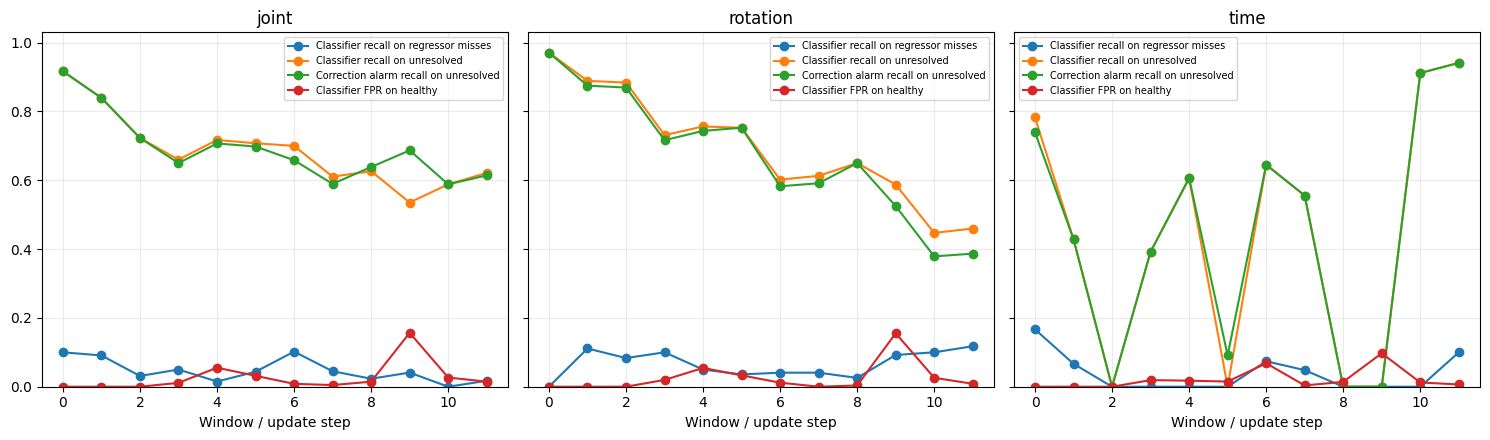

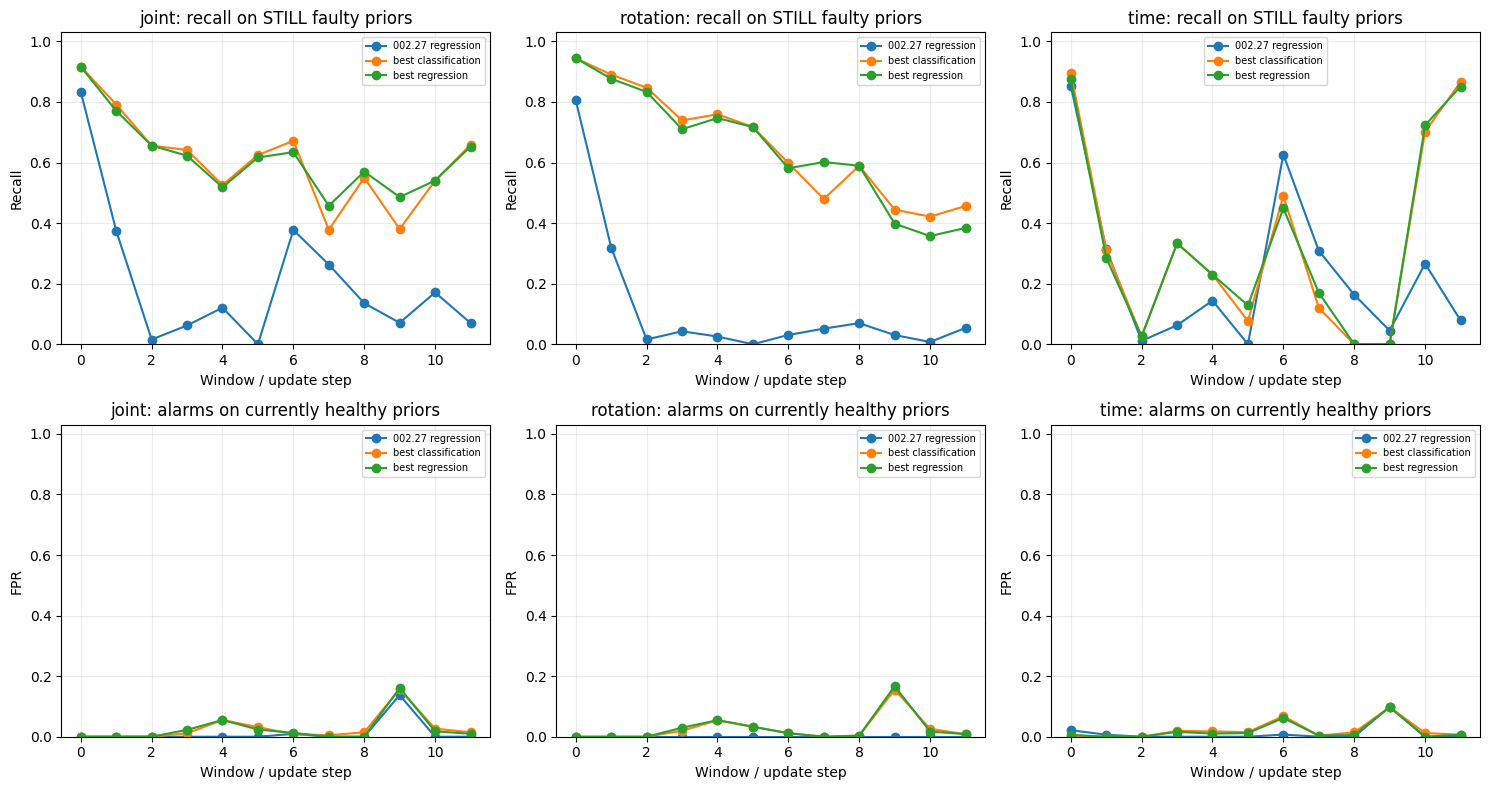

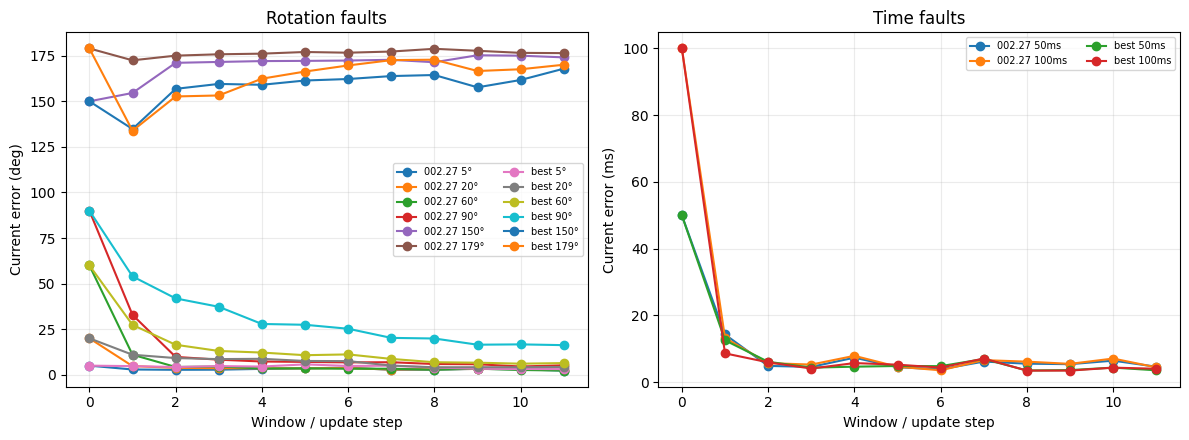

In [31]:
def rollout_cases(rng):
    cases=[]
    for key in CALIBRATION_KEYS:
        axis=rng.normal(size=3); axis/=np.linalg.norm(axis)
        for angle in ROLLOUT_ANGLES_DEG:
            if angle==0 and key!=CALIBRATION_KEYS[0]: continue
            cases.append(dict(source_row=0,rotations={k:float(angle) if k==key else 0. for k in CALIBRATION_KEYS},tau_ms={k:0. for k in CALIBRATION_KEYS},axes={k:axis if k==key else np.zeros(3) for k in CALIBRATION_KEYS},initial_sensor=key if angle else 'none',initial_angle_deg=float(angle),initial_tau_ms=0.))
        for tau in ROLLOUT_TIME_FAULT_MS:
            for sign in (-1,1):
                cases.append(dict(source_row=0,rotations={k:0. for k in CALIBRATION_KEYS},tau_ms={k:sign*float(tau) if k==key else 0. for k in CALIBRATION_KEYS},axes={k:np.zeros(3) for k in CALIBRATION_KEYS},initial_sensor=key,initial_angle_deg=0.,initial_tau_ms=sign*float(tau)))
    return cases


@torch.inference_mode()
def evaluate_rollouts(net,dataset,names,label,thresholds,include_classifier):
    net.eval(); rows=[]; rollout_id=0
    for seq_i,sequence in enumerate(names):
        available=np.asarray(dataset.window_indices_for_sequence(sequence),dtype=int)
        max_start=len(available)-ROLLOUT_NUM_WINDOWS
        if max_start<0: continue
        starts=np.unique(np.linspace(0,max_start,min(ROLLOUT_STARTS_PER_SEQUENCE,max_start+1)).round().astype(int))
        for start in starts:
            indices=available[start:start+ROLLOUT_NUM_WINDOWS]
            seed=TEST_AUG_SEED+500_000+seq_i*100_003+int(start)*1009
            windows=[]
            for idx in indices:
                raw=window_batch_to(collate_windows([dataset[int(idx)]]),DEVICE,dtype=MODEL_DTYPE)
                windows.append(fixed_seeded_physical(raw,seed))
            truth=windows[0].current_calibration
            for w in windows[1:]:
                for key in CALIBRATION_KEYS:
                    torch.testing.assert_close(w.current_calibration[key].transform,truth[key].transform,atol=3e-5,rtol=3e-5)
                    torch.testing.assert_close(w.current_calibration[key].time_offset,truth[key].time_offset,atol=3e-6,rtol=3e-6)
            cases=rollout_cases(np.random.default_rng(seed+51))
            for offset in range(0,len(cases),BATCH_SIZE):
                subset=cases[offset:offset+BATCH_SIZE]; n=len(subset)
                # faulted_window_from_cases copies measurements and sets prior; on later steps
                # replace that prior with the previous model update, never reinject the fault.
                states=faulted_window_from_cases(windows[0],subset).current_calibration
                for step,w in enumerate(windows):
                    repeated=faulted_window_from_cases(w,subset)
                    window=WindowBatch(streams=dict(repeated.streams),current_calibration=states,metadata=dict(repeated.metadata),targets=None,dataset_indices=None)
                    out=net(tokenize_window(window)); prob=out.logits.sigmoid()
                    if out.calibration_keys!=CALIBRATION_KEYS: raise AssertionError('Unexpected rollout key order')
                    updated={}
                    for j,key in enumerate(CALIBRATION_KEYS):
                        state=states[key]; pred=out.predictions[key]; R=state.transform[:,:3,:3]; gt_R=truth[key].transform[:,:3,:3].expand_as(R)
                        theta=distance_so3_deg(R,gt_R)
                        tau=1000.*(state.time_offset.reshape(-1)-truth[key].time_offset.reshape(-1)[0])
                        dR=pred.delta_rotation; dt=pred.delta_tau.reshape_as(state.time_offset)
                        magnitude=distance_so3_deg(dR,torch.eye(3,device=DEVICE,dtype=MODEL_DTYPE).expand_as(dR))
                        new_T=state.transform.clone(); new_T[:,:3,:3]=dR@R
                        updated[key]=CalibrationState(transform=new_T,time_offset=state.time_offset+dt)
                        residual=distance_so3_deg(new_T[:,:3,:3],gt_R)
                        for b,c in enumerate(subset):
                            rows.append(dict(checkpoint=label,sequence=sequence,start_index=int(indices[0]),rollout_id=rollout_id+b,step=step,sensor=key,initial_sensor=c['initial_sensor'],initial_angle_deg=c['initial_angle_deg'],initial_tau_ms=c['initial_tau_ms'],true_rotation_deg=float(theta[b]),true_tau_ms=float(tau[b]),predicted_rotation_deg=float(magnitude[b]),predicted_abs_tau_ms=float(dt.reshape(-1)[b].abs()*1000),residual_deg=float(residual[b]),tau_residual_ms=float(tau[b]+dt.reshape(-1)[b]*1000),target_rotation=int(theta[b]>GT_ROT_TOL_DEG),target_time=int(tau[b].abs()>GT_TAU_TOL_MS),target_joint=int((theta[b]>GT_ROT_TOL_DEG)|(tau[b].abs()>GT_TAU_TOL_MS)),prob_joint=float(prob[b,j,0]),prob_rotation=float(prob[b,j,1]),prob_time=float(prob[b,j,2])))
                    states=updated
                rollout_id+=n
            del windows
    if not rows: raise RuntimeError('No chronological rollout cases')
    df=pd.DataFrame(rows)
    for method in (('regression','classification') if include_classifier else ('regression',)):
        for task in TASKS:
            _,alarm=score_and_alarm(df,method,task,thresholds)
            df[f'alarm_{method}_{task}']=alarm
    return df


if RUN_ROLLOUT_EVALUATION:
    rollout_dataset,rollout_names,rollout_split=(test_dataset,TEST_NAMES,'test') if RUN_TEST_EVALUATION else (val_dataset,VAL_NAMES,'validation')
    threshold_path=RUN_DIR/('full_test_thresholds.json' if RUN_TEST_EVALUATION else 'full_validation_thresholds.json')
    thresholds=json.loads(threshold_path.read_text())
    probe=make_initial_model(); rollout_tables=[]; rollout_metric_rows=[]
    for label,path in {'002.27':None,'best':BEST_CHECKPOINT_PATH}.items():
        if path is None: probe.load_state_dict(initial_state,strict=True)
        else: load_joint_checkpoint(path,probe)
        df=evaluate_rollouts(probe,rollout_dataset,rollout_names,label,thresholds[label],path is not None)
        rollout_tables.append(df)
        for step,g in df.groupby('step'):
            for method in (('regression','classification') if path is not None else ('regression',)):
                for task in TASKS:
                    y=g[f'target_{task}'].to_numpy(bool); score,alarm=score_and_alarm(g,method,task,thresholds[label])
                    rollout_metric_rows.append(dict(checkpoint=label,step=step,method=method,task=task,**metrics_for_scores(y,score,alarm)))
        clear_cuda()
    del probe
    rollout_df=pd.concat(rollout_tables,ignore_index=True); rollout_metrics=pd.DataFrame(rollout_metric_rows)
    rollout_df.to_csv(RUN_DIR/f'{rollout_split}_rollout_scores.csv',index=False)
    rollout_metrics.to_csv(RUN_DIR/f'{rollout_split}_rollout_detection.csv',index=False)
    display(rollout_metrics.round(3))
    # Directly answer the deployment question: does the classifier recover faults
    # missed by correction magnitude, and does it still alarm on stalled updates?
    hybrid_rows = rollout_df[rollout_df.checkpoint=='best'].copy()
    rescue_rows = []
    for step,g in hybrid_rows.groupby('step'):
        for task in TASKS:
            y=g[f'target_{task}'].to_numpy(bool)
            reg_alarm=g[f'alarm_regression_{task}'].to_numpy(bool)
            cls_alarm=g[f'alarm_classification_{task}'].to_numpy(bool)
            still_wrong = (g.residual_deg > GT_ROT_TOL_DEG).to_numpy() if task=='rotation' else (g.tau_residual_ms.abs() > GT_TAU_TOL_MS).to_numpy()
            if task=='joint': still_wrong=((g.residual_deg > GT_ROT_TOL_DEG)|(g.tau_residual_ms.abs() > GT_TAU_TOL_MS)).to_numpy()
            missed=y & ~reg_alarm
            unresolved=y & still_wrong
            def fraction(mask, flag): return float(flag[mask].mean()) if mask.any() else np.nan
            rescue_rows.append(dict(step=step,task=task,currently_faulty=int(y.sum()),regression_missed=int(missed.sum()),classifier_rescued=int((missed & cls_alarm).sum()),rescue_rate=fraction(missed,cls_alarm),unresolved_after_update=int(unresolved.sum()),classifier_recall_on_unresolved=fraction(unresolved,cls_alarm),correction_alarm_recall_on_unresolved=fraction(unresolved,reg_alarm),classifier_fpr_on_currently_healthy=fraction(~y,cls_alarm)))
    rollout_rescue=pd.DataFrame(rescue_rows)
    rollout_rescue.to_csv(RUN_DIR/f'{rollout_split}_rollout_classifier_rescue.csv',index=False)
    display(rollout_rescue.round(3))
    fig,axes=plt.subplots(1,3,figsize=(15,4.5),sharey=True)
    for ax,task in zip(axes,TASKS):
        g=rollout_rescue[rollout_rescue.task==task]
        for field,label in (('rescue_rate','Classifier recall on regressor misses'),('classifier_recall_on_unresolved','Classifier recall on unresolved'),('correction_alarm_recall_on_unresolved','Correction alarm recall on unresolved'),('classifier_fpr_on_currently_healthy','Classifier FPR on healthy')):
            ax.plot(g.step,g[field],'-o',label=label)
        ax.set(title=task,xlabel='Window / update step',ylim=(0,1.03)); ax.grid(alpha=.25); ax.legend(fontsize=7)
    finish_figure(fig,f'{rollout_split}_rollout_classifier_rescue.png')
    fig,axes=plt.subplots(2,3,figsize=(15,8))
    for j,task in enumerate(TASKS):
        for (label,method),g in rollout_metrics[rollout_metrics.task==task].groupby(['checkpoint','method']):
            axes[0,j].plot(g.step,g.recall,'-o',label=f'{label} {method}'); axes[1,j].plot(g.step,g.false_positive_rate,'-o',label=f'{label} {method}')
        axes[0,j].set(title=f'{task}: recall on STILL faulty priors',ylabel='Recall',ylim=(0,1.03)); axes[1,j].set(title=f'{task}: alarms on currently healthy priors',ylabel='FPR',ylim=(0,1.03))
        for ax in axes[:,j]: ax.set_xlabel('Window / update step'); ax.grid(alpha=.25); ax.legend(fontsize=7)
    finish_figure(fig,f'{rollout_split}_rollout_fault_detection.png')
    fig,axes=plt.subplots(1,2,figsize=(12,4.5))
    selected=rollout_df[rollout_df.sensor==rollout_df.initial_sensor]
    for (label,angle),g in selected[selected.initial_angle_deg>0].groupby(['checkpoint','initial_angle_deg']):
        curve=g.groupby('step').true_rotation_deg.median(); axes[0].plot(curve.index,curve,'-o',label=f'{label} {angle:g}°')
    for (label,tau),g in selected[selected.initial_tau_ms!=0].assign(initial_abs_tau=lambda d:d.initial_tau_ms.abs()).groupby(['checkpoint','initial_abs_tau']):
        curve=g.assign(abs_tau=g.true_tau_ms.abs()).groupby('step').abs_tau.median(); axes[1].plot(curve.index,curve,'-o',label=f'{label} {tau:g}ms')
    for ax,title,ylabel in zip(axes,('Rotation faults','Time faults'),('Current error (deg)','Current error (ms)')):
        ax.set(title=title,xlabel='Window / update step',ylabel=ylabel); ax.grid(alpha=.25); ax.legend(fontsize=7,ncol=2)
    finish_figure(fig,f'{rollout_split}_rollout_residuals.png')
    clear_cuda()

## Interpretation

- A useful joint model should retain the original regressor's residual distributions while improving fault AP, K=1 localization and K=0 specificity. Do not treat high initial F1 as evidence of learning; inspect AP against prevalence and compare correction scores on identical inputs.
- `best.pt` is a compromise, not a guaranteed regression-retention constraint. Compare `best_classification.pt` and `best_regression.pt` to see whether a trade-off exists. Adjust the loss weights only after looking at these curves. Regression heads for translation/change event, if present, are kept but are not supervised by this experiment.
- The 3°/10 ms tolerances are the target definition; regression decision thresholds and classifier thresholds are independently tuned on validation. Test and controlled-sweep results must not be used for threshold tuning.
- Rollout recall is measured against the **current** prior error. If no priors remain faulty at a later step, recall is undefined rather than perfect. The joint classifier can be useful if its recall stays high when the correction-magnitude detector misses remaining errors. It must also avoid false alarms when the prior has become accurate.
- Stochastic results are small-sample diagnostics, not final results; the full test split and matched angle sweep are the main comparisons.

In [32]:
# %% A1. Paired rotation rollouts: configuration and inference
# Run Notebook 78's setup/helper cells through section 17 (definitions of
# rollout_cases and evaluate_rollouts). RUN_ROLLOUT_EVALUATION may be False.
# No training or threshold fitting is performed by this appendix.

APP_ROLLOUT_SPLIT = 'validation'  # 'test' for the final held-out experiment
APP_ROLLOUT_ANGLES = (0., 5., 10., 20., 45., 90., 150., 179.)
APP_ROLLOUT_WINDOWS = 12
APP_ROLLOUT_STARTS = 4  # per sequence; actual consecutive windows per rollout
APP_ROLLOUT_RUN_INFERENCE = True
APP_ROLLOUT_CLASSIFIER_THRESHOLD = 0.5  # replace with a fixed validation-selected threshold if desired
APP_ROLLOUT_CHECKPOINT = BEST_CHECKPOINT_PATH

# Plot one matched example per angle, or aggregate independent rollouts.
APP_ROLLOUT_VIEW = 'individual'  # 'individual' or 'aggregate'
APP_ROLLOUT_SENSOR = 'lidar'  # 'imu', 'lidar', 'lidar_right', or 'all' (aggregate only)
APP_ROLLOUT_EXAMPLE = 0  # index in the printed sequence/start table

APP_ROLLOUT_DIR = RUN_DIR / 'appendix_rollout_angle_comparison'
APP_ROLLOUT_DIR.mkdir(parents=True, exist_ok=True)
APP_ROLLOUT_CSV = APP_ROLLOUT_DIR / f'{APP_ROLLOUT_SPLIT}_paired_rollout_scores.csv'
APP_ROLLOUT_META = APP_ROLLOUT_CSV.with_suffix('.json')

if APP_ROLLOUT_SPLIT not in ('validation', 'test'):
    raise ValueError('APP_ROLLOUT_SPLIT must be validation or test.')
if APP_ROLLOUT_WINDOWS < 1 or APP_ROLLOUT_STARTS < 1:
    raise ValueError('Positive rollout length and number of starts required.')
if not APP_ROLLOUT_ANGLES or len(set(APP_ROLLOUT_ANGLES)) != len(APP_ROLLOUT_ANGLES) or any(not 0 <= a <= 180 for a in APP_ROLLOUT_ANGLES):
    raise ValueError('Provide unique initial rotation angles in [0, 180].')
if not 0 <= APP_ROLLOUT_CLASSIFIER_THRESHOLD <= 1:
    raise ValueError('Invalid classifier threshold.')

app_dataset, app_names = (val_dataset, VAL_NAMES) if APP_ROLLOUT_SPLIT == 'validation' else (test_dataset, TEST_NAMES)
app_settings = dict(split=APP_ROLLOUT_SPLIT, names=list(app_names), angles=list(APP_ROLLOUT_ANGLES), windows=APP_ROLLOUT_WINDOWS, starts=APP_ROLLOUT_STARTS, signature=signature, checkpoint=str(APP_ROLLOUT_CHECKPOINT), checkpoint_mtime_ns=APP_ROLLOUT_CHECKPOINT.stat().st_mtime_ns, checkpoint_size=APP_ROLLOUT_CHECKPOINT.stat().st_size)

if APP_ROLLOUT_RUN_INFERENCE:
    # Reuse Notebook 78's real chronological rollout implementation. Disable time
    # fault injection, but keep its original rotation AND time update behavior.
    old_rollout_settings = ROLLOUT_NUM_WINDOWS, ROLLOUT_STARTS_PER_SEQUENCE, ROLLOUT_ANGLES_DEG, ROLLOUT_TIME_FAULT_MS
    probe = None
    tables = []
    try:
        ROLLOUT_NUM_WINDOWS = APP_ROLLOUT_WINDOWS
        ROLLOUT_STARTS_PER_SEQUENCE = APP_ROLLOUT_STARTS
        ROLLOUT_ANGLES_DEG = tuple(APP_ROLLOUT_ANGLES)
        ROLLOUT_TIME_FAULT_MS = ()
        probe = make_initial_model()
        for label, path in (('002.27', None), ('best', APP_ROLLOUT_CHECKPOINT)):
            if path is None:
                probe.load_state_dict(initial_state, strict=True)
            else:
                state = load_joint_checkpoint(path, probe)
                print(f'Best checkpoint: step/epoch {state["step"]}')
                del state
            print(f'Running {label} on {APP_ROLLOUT_SPLIT} ...', flush=True)
            thresholds = default_thresholds()
            thresholds['classification']['rotation'] = APP_ROLLOUT_CLASSIFIER_THRESHOLD
            tables.append(evaluate_rollouts(probe, app_dataset, app_names, label, thresholds, include_classifier=path is not None))
            clear_cuda()
    finally:
        ROLLOUT_NUM_WINDOWS, ROLLOUT_STARTS_PER_SEQUENCE, ROLLOUT_ANGLES_DEG, ROLLOUT_TIME_FAULT_MS = old_rollout_settings
        del probe
        clear_cuda()
    app_rollout_df = pd.concat(tables, ignore_index=True)
    # The baseline's random auxiliary classifier is NOT a trained predictor.
    app_rollout_df.loc[app_rollout_df.checkpoint == '002.27', ['prob_joint', 'prob_rotation', 'prob_time']] = np.nan
else:
    if json.loads(APP_ROLLOUT_META.read_text()) != app_settings:
        raise ValueError('Cached rollouts do not match the current checkpoint or inference settings. Rerun inference.')
    app_rollout_df = pd.read_csv(APP_ROLLOUT_CSV, keep_default_na=True)

# Both models must have the same initial conditions and measurement windows.
match_cols = ['sequence', 'start_index', 'rollout_id', 'initial_sensor', 'initial_angle_deg', 'initial_tau_ms', 'step', 'sensor']
base = app_rollout_df.loc[app_rollout_df.checkpoint == '002.27'].set_index(match_cols).sort_index()
best = app_rollout_df.loc[app_rollout_df.checkpoint == 'best'].set_index(match_cols).sort_index()
if base.empty or not base.index.is_unique or not best.index.is_unique or not base.index.equals(best.index):
    raise AssertionError('The two rollout models do not have identical case keys.')
initial = base.index.get_level_values('step') == 0
np.testing.assert_allclose(base.loc[initial, 'true_rotation_deg'], best.loc[initial, 'true_rotation_deg'], atol=0.05, rtol=0)
np.testing.assert_allclose(base.loc[initial, 'true_tau_ms'], best.loc[initial, 'true_tau_ms'], atol=0.01, rtol=0)
if not np.isfinite(app_rollout_df[['true_rotation_deg', 'residual_deg', 'predicted_rotation_deg']].to_numpy(float)).all() or not np.isfinite(best['prob_rotation'].to_numpy(float)).all():
    raise ValueError('Non-finite rotation predictions.')
trajectory_cols = ['checkpoint', 'sequence', 'start_index', 'rollout_id', 'sensor']
step_checks = app_rollout_df.groupby(trajectory_cols).step.agg(['size', 'nunique', 'min', 'max'])
if not ((step_checks['size'] == APP_ROLLOUT_WINDOWS) & (step_checks['nunique'] == APP_ROLLOUT_WINDOWS) & (step_checks['min'] == 0) & (step_checks['max'] == APP_ROLLOUT_WINDOWS - 1)).all():
    raise AssertionError('Incomplete rollout trajectory.')

if APP_ROLLOUT_RUN_INFERENCE:
    app_rollout_df.to_csv(APP_ROLLOUT_CSV, index=False)
    APP_ROLLOUT_META.write_text(json.dumps(app_settings, indent=2))

app_start_table = app_rollout_df[['sequence', 'start_index']].drop_duplicates().sort_values(['sequence', 'start_index']).reset_index(drop=True)
print('Matched rollout starts (choose APP_ROLLOUT_EXAMPLE by row index):')
display(app_start_table)



Running 002.27 on validation ...
Best checkpoint: step/epoch 78
Running best on validation ...
Matched rollout starts (choose APP_ROLLOUT_EXAMPLE by row index):


,sequence,start_index
0,Urban26,0
1,Urban26,27
2,Urban26,55
3,Urban26,82
4,Urban28,94
5,Urban28,198
6,Urban28,302
7,Urban28,406


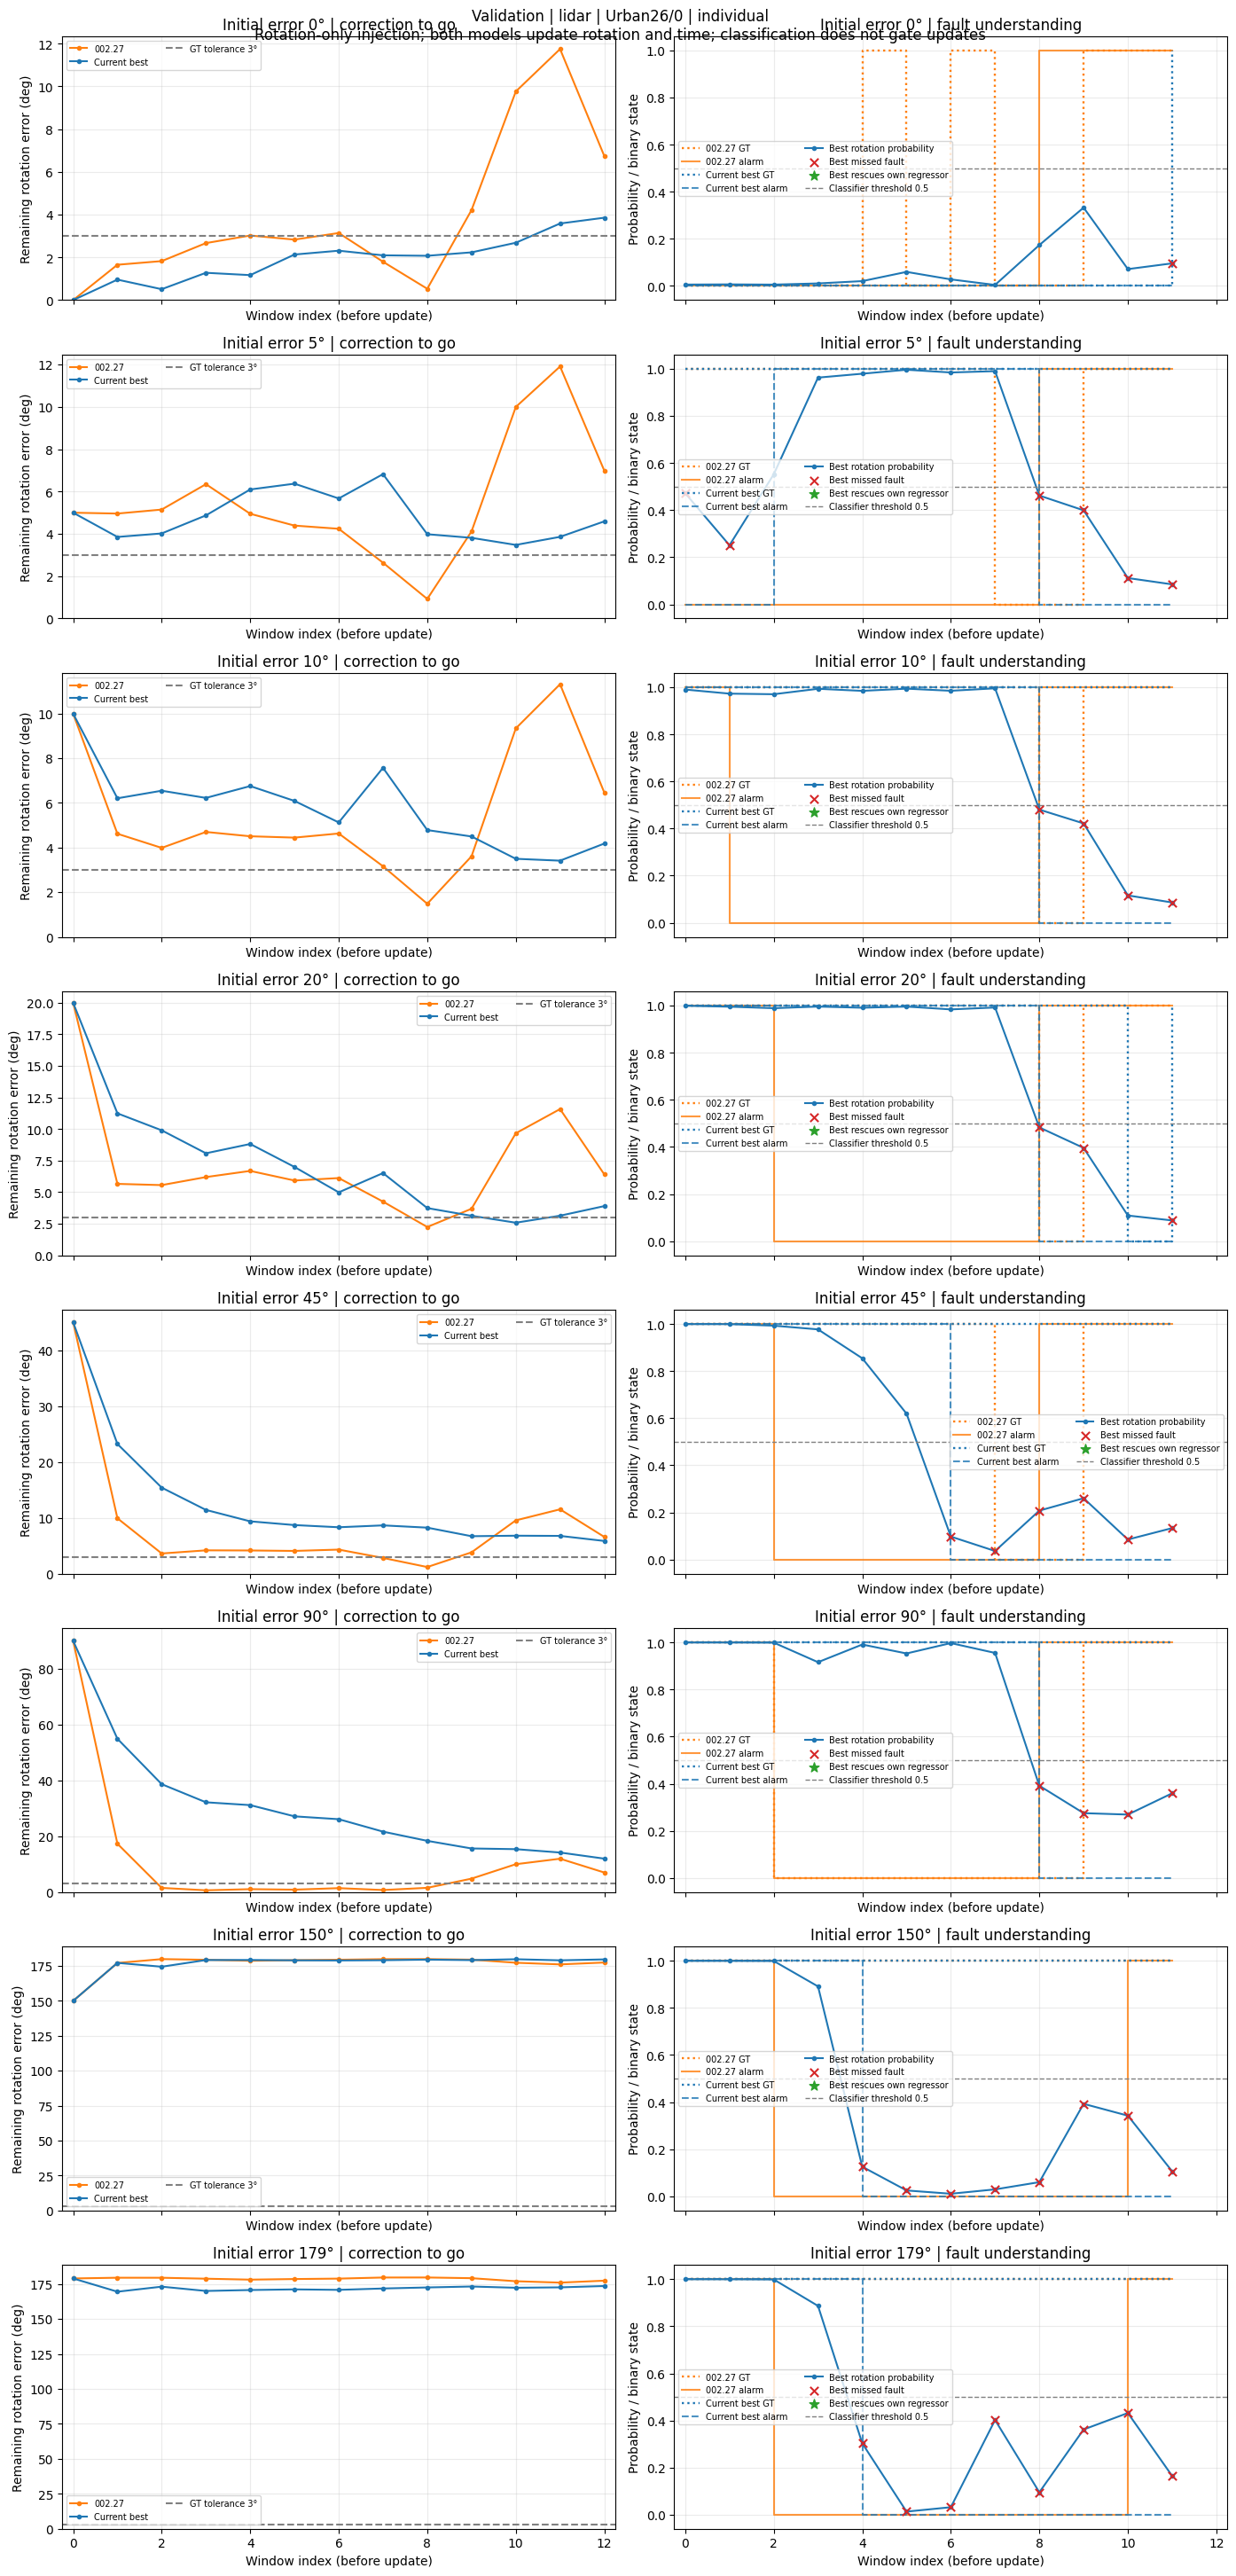

Final observed window (before its update):


,checkpoint,initial_angle_deg,step,n_predictions,n_correct,n_faults,n_alarms,n_missed,n_false_alarms,n_rescued,median_ctg_deg,accuracy
11,002.27,0.0,11,1,1,1,1,0,0,0,11.751,1.0
23,002.27,5.0,11,1,1,1,1,0,0,0,11.912,1.0
35,002.27,10.0,11,1,1,1,1,0,0,0,11.320,1.0
47,002.27,20.0,11,1,1,1,1,0,0,0,11.581,1.0
59,002.27,45.0,11,1,1,1,1,0,0,0,11.509,1.0
71,002.27,90.0,11,1,1,1,1,0,0,0,11.924,1.0
83,002.27,150.0,11,1,1,1,1,0,0,0,176.125,1.0
95,002.27,179.0,11,1,1,1,1,0,0,0,176.017,1.0
107,best,0.0,11,1,0,1,0,1,0,0,3.585,0.0
119,best,5.0,11,1,0,1,0,1,0,0,3.858,0.0


In [33]:
# %% A2. Plot CTG and fault understanding for each initial angle
# You can rerun only this cell after changing the view, sensor, example or
# classifier threshold. Raw predictions are reused, no inference needed.

if APP_ROLLOUT_VIEW not in ('individual', 'aggregate'):
    raise ValueError('Choose individual or aggregate.')
if APP_ROLLOUT_SENSOR not in (*CALIBRATION_KEYS, 'all'):
    raise ValueError('Unknown sensor.')
if APP_ROLLOUT_VIEW == 'individual' and APP_ROLLOUT_SENSOR == 'all':
    raise ValueError('Select a particular sensor for individual plots.')
if not 0 <= APP_ROLLOUT_CLASSIFIER_THRESHOLD <= 1:
    raise ValueError('Invalid classifier threshold.')

app_plot_df = app_rollout_df.copy()
# In K=1 plot the originally injected sensor; at 0 degrees use the selected
# clean sensor (or all three in the aggregate all-sensor view).
selected = (app_plot_df.initial_sensor == app_plot_df.sensor) | (app_plot_df.initial_angle_deg == 0)
app_plot_df = app_plot_df.loc[selected].copy()
if APP_ROLLOUT_SENSOR != 'all':
    app_plot_df = app_plot_df.loc[app_plot_df.sensor == APP_ROLLOUT_SENSOR].copy()

if APP_ROLLOUT_VIEW == 'individual':
    if not 0 <= APP_ROLLOUT_EXAMPLE < len(app_start_table):
        raise IndexError('APP_ROLLOUT_EXAMPLE is outside the available starts.')
    example = app_start_table.iloc[APP_ROLLOUT_EXAMPLE]
    app_plot_df = app_plot_df.loc[(app_plot_df.sequence == example.sequence) & (app_plot_df.start_index == example.start_index)].copy()
    view_label = f'{example.sequence}/{example.start_index}'
else:
    view_label = f'{len(app_start_table)} matched starts'

# IMPORTANT: the GT state follows each model's OWN current error, not the
# initial injected angle, nor the other model's trajectory.
app_plot_df['gt_fault'] = app_plot_df.true_rotation_deg > GT_ROT_TOL_DEG
app_plot_df['reg_alarm'] = app_plot_df.predicted_rotation_deg > GT_ROT_TOL_DEG
app_plot_df['cls_alarm'] = app_plot_df.prob_rotation >= APP_ROLLOUT_CLASSIFIER_THRESHOLD
app_plot_df['alarm'] = np.where(app_plot_df.checkpoint == '002.27', app_plot_df.reg_alarm, app_plot_df.cls_alarm)
app_plot_df['correct'] = app_plot_df.alarm == app_plot_df.gt_fault
app_plot_df['missed'] = app_plot_df.gt_fault & ~app_plot_df.alarm
app_plot_df['false_alarm'] = ~app_plot_df.gt_fault & app_plot_df.alarm
app_plot_df['rescued'] = app_plot_df.gt_fault & ~app_plot_df.reg_alarm & app_plot_df.cls_alarm & (app_plot_df.checkpoint == 'best')

colors = {'002.27': 'tab:orange', 'best': 'tab:blue'}
labels = {'002.27': '002.27', 'best': 'Current best'}
angles = sorted(app_plot_df.initial_angle_deg.unique())
if not angles:
    raise ValueError('No matching rollouts for this plot selection.')
fig, axes = plt.subplots(len(angles), 2, figsize=(14, 3.7 * len(angles)), squeeze=False, sharex=True)
for row, angle in enumerate(angles):
    left, right = axes[row]
    part = app_plot_df.loc[app_plot_df.initial_angle_deg == angle]
    for label in ('002.27', 'best'):
        g = part.loc[part.checkpoint == label]
        if g.empty:
            raise AssertionError(f'Missing {label} rollout at {angle} degrees.')
        c = colors[label]
        if APP_ROLLOUT_VIEW == 'individual':
            if g.step.duplicated().any():
                raise AssertionError('Individual view contains multiple trajectories.')
            g = g.sort_values('step')
            x = g.step.to_numpy(int)
            # At index N there is only the last updated calibration, no new prediction.
            left.plot(np.r_[x, x[-1] + 1], np.r_[g.true_rotation_deg.to_numpy(), g.residual_deg.iloc[-1]], '-o', color=c, label=labels[label], markersize=3)
            right.step(x, g.gt_fault.astype(float), where='post', color=c, linestyle=':', linewidth=1.7, label=f'{labels[label]} GT')
            right.step(x, g.alarm.astype(float), where='post', color=c, linestyle='-' if label == '002.27' else '--', alpha=0.8, label=f'{labels[label]} alarm')
            if label == 'best':
                right.plot(x, g.prob_rotation, '-o', color=c, linewidth=1.5, markersize=3, label='Best rotation probability')
                # Show missed detections and rescues on the actual hybrid trajectory.
                missed = g.missed.to_numpy(bool)
                rescued = g.rescued.to_numpy(bool)
                right.scatter(x[missed], g.prob_rotation.to_numpy()[missed], marker='x', color='tab:red', s=45, zorder=5, label='Best missed fault')
                right.scatter(x[rescued], g.prob_rotation.to_numpy()[rescued], marker='*', color='tab:green', s=65, zorder=5, label='Best rescues own regressor')
        else:
            q = g.groupby('step').true_rotation_deg.quantile([.1, .5, .9]).unstack().sort_index()
            last = g.loc[g.step == APP_ROLLOUT_WINDOWS - 1, 'residual_deg'].quantile([.1, .5, .9])
            q.loc[APP_ROLLOUT_WINDOWS] = last
            x = q.index.to_numpy(int)
            left.plot(x, q[.5].to_numpy(float), '-o', color=c, label=labels[label], markersize=3)
            left.fill_between(x, q[.1].to_numpy(float), q[.9].to_numpy(float), color=c, alpha=.14)
            # Sum individual decisions before division; never threshold an averaged score.
            counts = g.groupby('step').agg(n=('alarm', 'size'), alarms=('alarm', 'sum'), faults=('gt_fault', 'sum'))
            right.plot(counts.index, counts.alarms / counts.n, '-o', color=c, markersize=3, label=f'{labels[label]} alarm fraction')
            right.plot(counts.index, counts.faults / counts.n, ':', color=c, linewidth=1.8, label=f'{labels[label]} true fault fraction')
            if label == 'best':
                p = g.groupby('step').prob_rotation.mean()
                right.plot(p.index, p, '--', color=c, alpha=.7, label='Best mean probability (not thresholded)')
    left.axhline(GT_ROT_TOL_DEG, color='gray', linestyle='--', label=f'GT tolerance {GT_ROT_TOL_DEG:g}°')
    left.set(title=f'Initial error {angle:g}° | correction to go', ylabel='Remaining rotation error (deg)', ylim=(0, None))
    right.axhline(APP_ROLLOUT_CLASSIFIER_THRESHOLD, color='gray', linestyle='--', linewidth=1, label=f'Classifier threshold {APP_ROLLOUT_CLASSIFIER_THRESHOLD:g}')
    right.set(title=f'Initial error {angle:g}° | fault understanding', ylabel='Probability / binary state' if APP_ROLLOUT_VIEW == 'individual' else 'Probability / fraction', ylim=(-.06, 1.06))
    for ax in (left, right):
        ax.set(xlabel='Window index (before update)', xlim=(-.25, APP_ROLLOUT_WINDOWS + .25))
        ax.grid(alpha=.25)
        ax.legend(fontsize=7, loc='best', ncol=2)
fig.suptitle(f'{APP_ROLLOUT_SPLIT.title()} | {APP_ROLLOUT_SENSOR} | {view_label} | {APP_ROLLOUT_VIEW}\nRotation-only injection; both models update rotation and time; classification does not gate updates', fontsize=12)
fig.tight_layout()
if SAVE_PLOTS:
    fig.savefig(APP_ROLLOUT_DIR / f'{APP_ROLLOUT_SPLIT}_{APP_ROLLOUT_SENSOR}_{APP_ROLLOUT_VIEW}_{APP_ROLLOUT_EXAMPLE}_ctg_and_fault.png', dpi=PLOT_DPI, bbox_inches='tight')
if SHOW_PLOTS: plt.show()
else: plt.close(fig)

# Counts refer to individual sensor/window decisions, not averaged probabilities.
app_rollout_summary = app_plot_df.groupby(['checkpoint', 'initial_angle_deg', 'step'], as_index=False).agg(n_predictions=('correct', 'size'), n_correct=('correct', 'sum'), n_faults=('gt_fault', 'sum'), n_alarms=('alarm', 'sum'), n_missed=('missed', 'sum'), n_false_alarms=('false_alarm', 'sum'), n_rescued=('rescued', 'sum'), median_ctg_deg=('true_rotation_deg', 'median'))
app_rollout_summary['accuracy'] = app_rollout_summary.n_correct / app_rollout_summary.n_predictions
app_rollout_summary.to_csv(APP_ROLLOUT_DIR / f'{APP_ROLLOUT_SPLIT}_{APP_ROLLOUT_SENSOR}_{APP_ROLLOUT_VIEW}_{APP_ROLLOUT_EXAMPLE}_metrics.csv', index=False)
print('Final observed window (before its update):')
display(app_rollout_summary.loc[app_rollout_summary.step == APP_ROLLOUT_WINDOWS - 1].round(3))


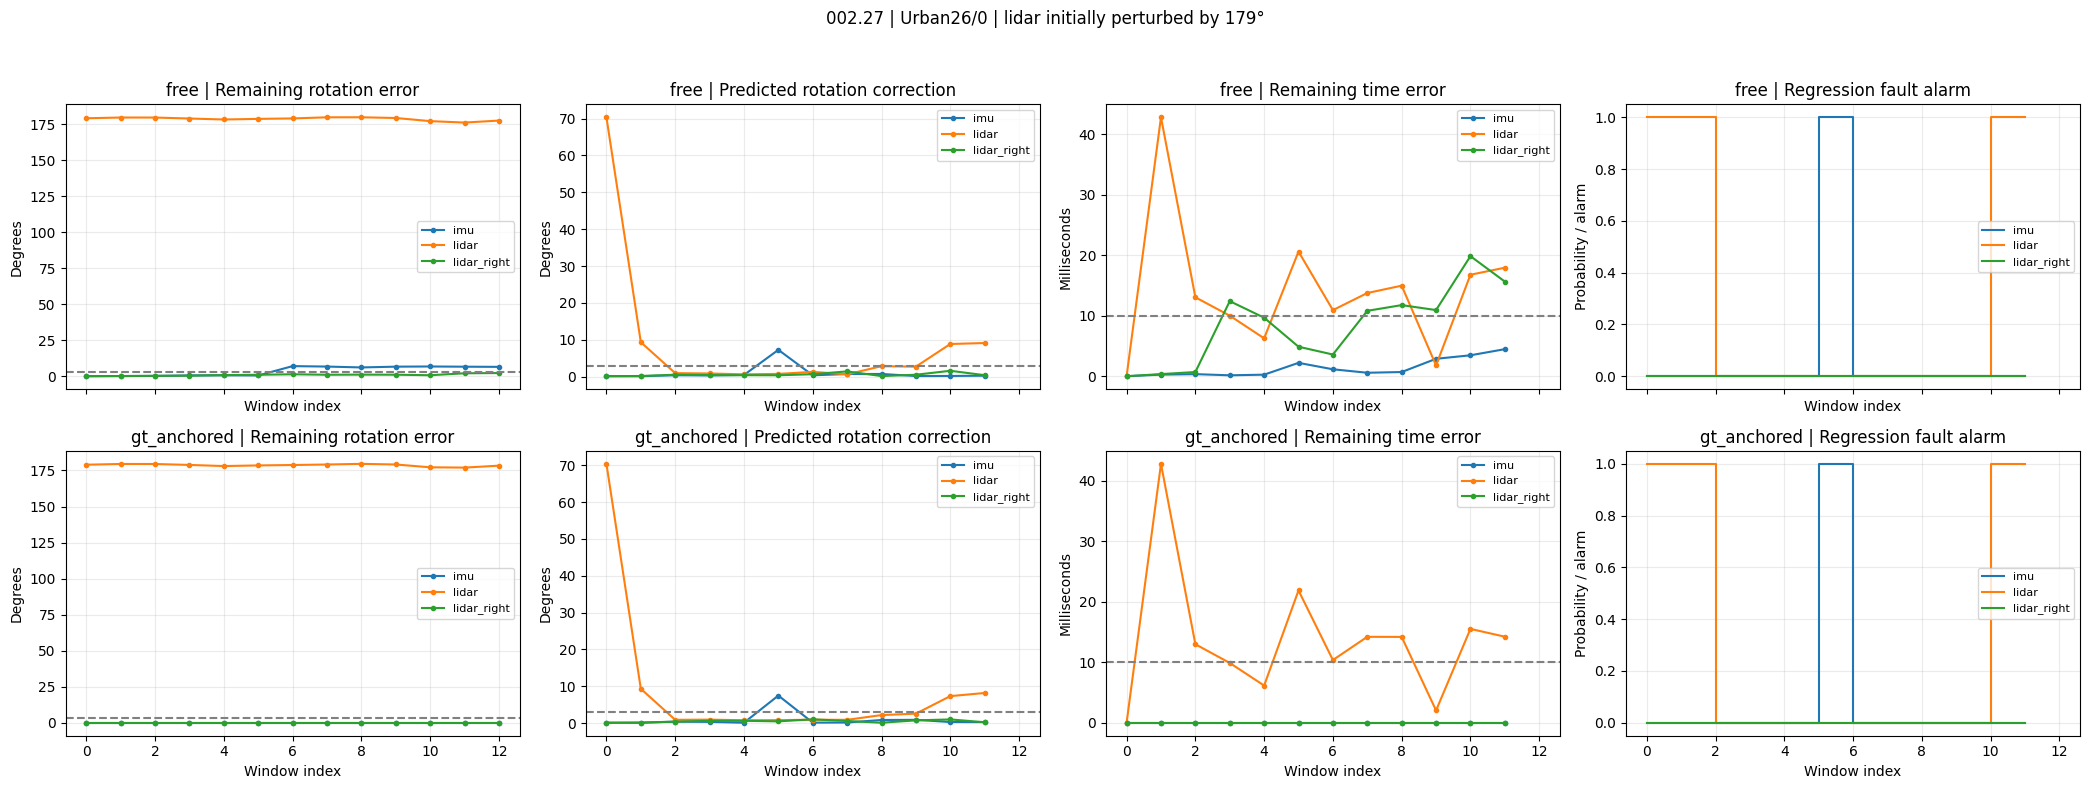

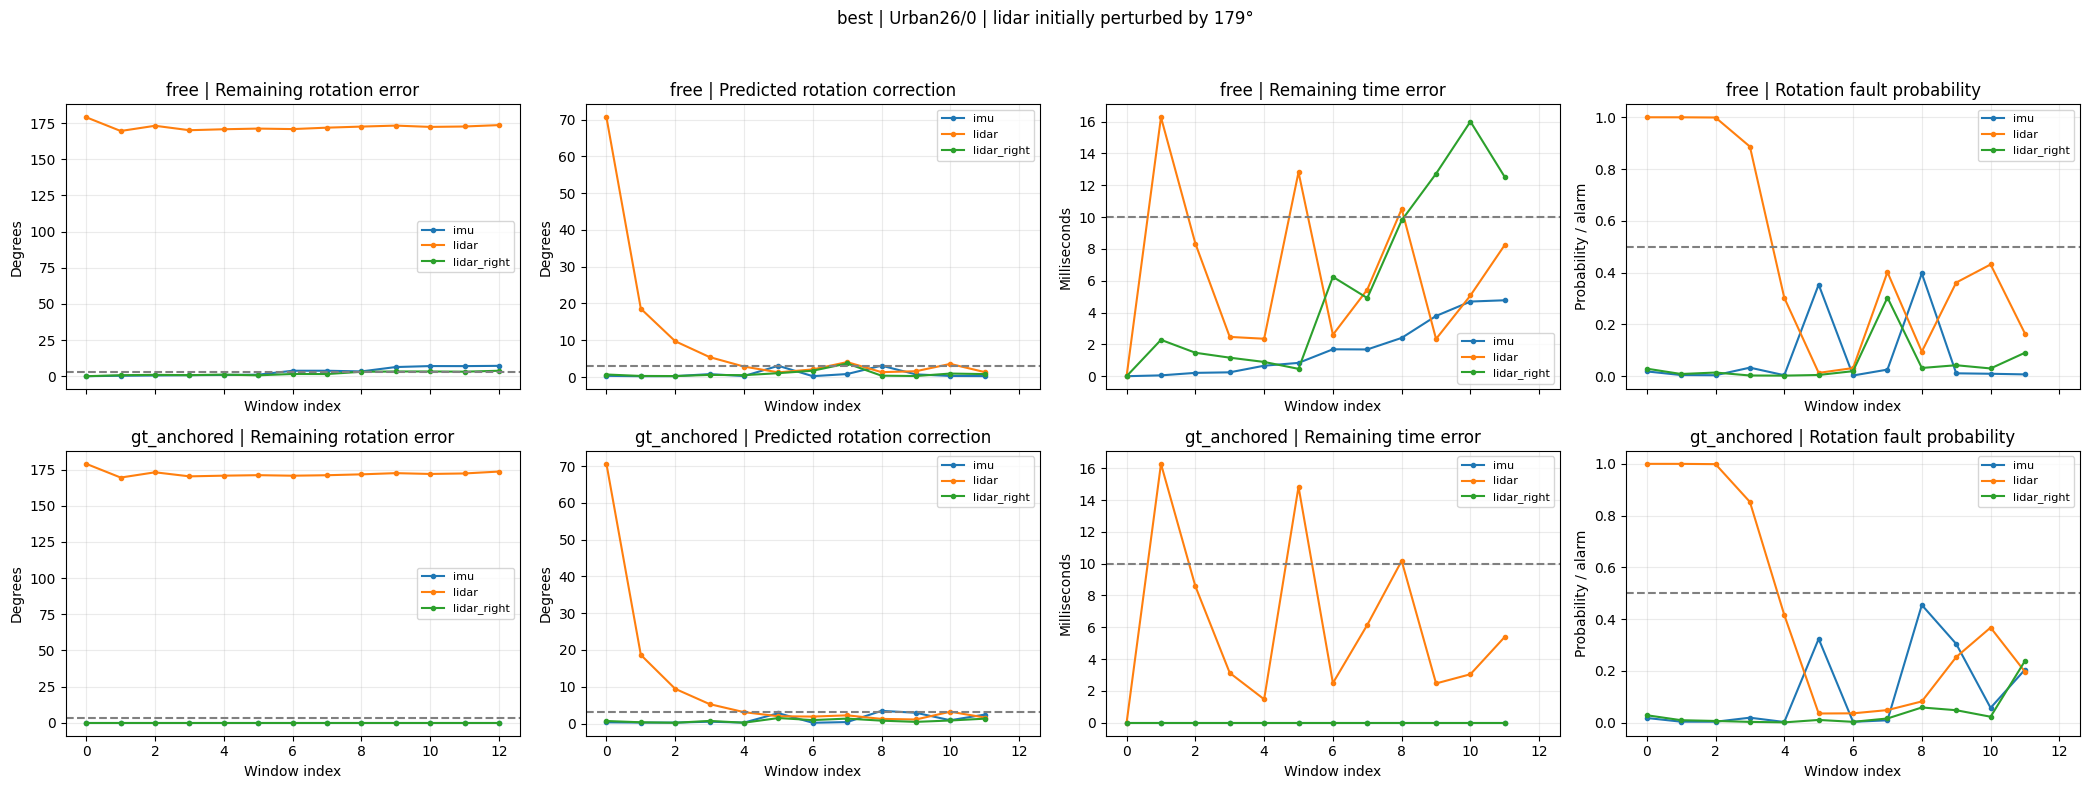

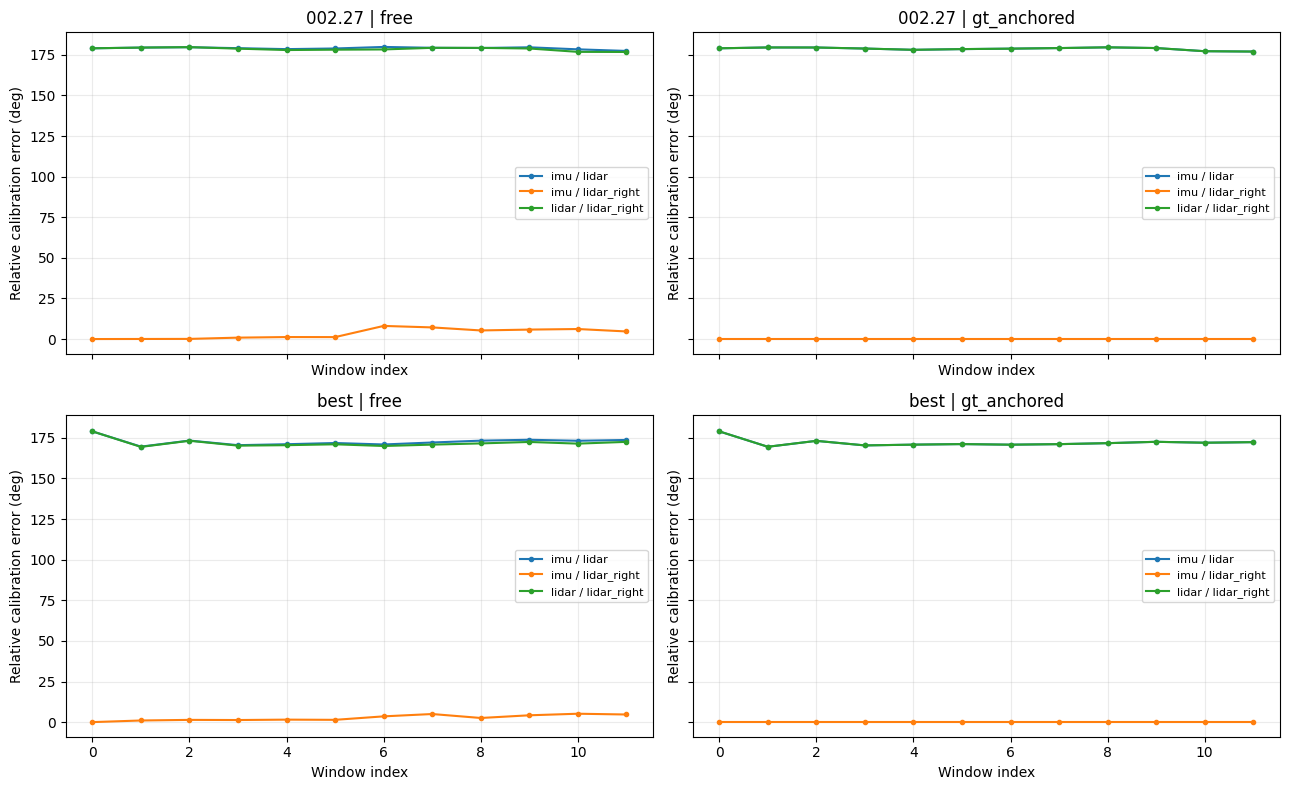

,checkpoint,mode,sensor,initial_error,max_error,final_error,mean_correction,max_correction,max_time_error,max_time_correction,mean_probability,n_correct,n_predictions,accuracy
0,002.27,free,imu,0.0,6.996,6.484,0.908,7.252,4.471,3.570,NaN,5,12,0.417
1,002.27,free,lidar,179.0,179.688,177.406,9.013,70.355,42.807,42.807,NaN,4,12,0.333
2,002.27,free,lidar_right,0.0,2.027,2.189,0.545,1.572,19.850,22.561,NaN,12,12,1.000
3,002.27,gt_anchored,imu,0.0,0.000,0.000,0.938,7.483,0.000,3.312,NaN,11,12,0.917
4,002.27,gt_anchored,lidar,179.0,179.598,178.339,8.771,70.355,42.807,42.807,NaN,4,12,0.333
5,002.27,gt_anchored,lidar_right,0.0,0.000,0.000,0.516,1.033,0.000,14.623,NaN,12,12,1.000
6,best,free,imu,0.0,7.007,7.163,0.857,3.091,4.773,6.194,0.073,6,12,0.500
7,best,free,lidar,179.0,179.000,173.587,10.200,70.619,16.274,16.274,0.474,4,12,0.333
8,best,free,lidar_right,0.0,3.273,3.765,0.928,3.684,16.006,14.711,0.048,8,12,0.667
9,best,gt_anchored,imu,0.0,0.000,0.000,1.218,3.441,0.000,5.638,0.117,12,12,1.000


In [34]:
# %% A3. Free versus GT-anchored calibration rollout

ANCHOR_SENSOR = 'lidar'
ANCHOR_ANGLE_DEG = 179.
ANCHOR_EXAMPLE = 0
ANCHOR_UPDATE_TIME = True

ANCHOR_MODES = ('free', 'gt_anchored')

example = app_start_table.iloc[ANCHOR_EXAMPLE]
sequence = example.sequence
seq_i = list(app_names).index(sequence)

available = np.asarray(app_dataset.window_indices_for_sequence(sequence), dtype=int)
start = int(np.flatnonzero(available == int(example.start_index))[0])
indices = available[start:start + APP_ROLLOUT_WINDOWS]

seed = TEST_AUG_SEED + 500_000 + seq_i * 100_003 + start * 1009


@torch.inference_mode()
def evaluate_anchored_rollout(net, windows, case, label, mode):
    """Compare unrestricted updates against fixed healthy calibration anchors."""
    net.eval()
    rows = []

    truth = windows[0].current_calibration
    states = faulted_window_from_cases(windows[0], [case]).current_calibration

    for step, physical in enumerate(windows):
        repeated = faulted_window_from_cases(physical, [case])

        window = WindowBatch(
            streams=dict(repeated.streams),
            current_calibration=states,
            metadata=dict(repeated.metadata),
            targets=None,
            dataset_indices=None,
        )

        out = net(tokenize_window(window))
        probabilities = out.logits.sigmoid()

        updated = {}

        # Left-multiplicative calibration error rotations.
        error_rotations = {
            key: states[key].transform[:, :3, :3] @ truth[key].transform[:, :3, :3].transpose(-1, -2)
            for key in CALIBRATION_KEYS
        }

        for j, key in enumerate(CALIBRATION_KEYS):
            state = states[key]
            gt = truth[key]
            pred = out.predictions[key]

            R = state.transform[:, :3, :3]
            R_gt = gt.transform[:, :3, :3]

            dR = pred.delta_rotation
            dt = pred.delta_tau.reshape_as(state.time_offset)
            eye = torch.eye(3, device=dR.device, dtype=dR.dtype).expand_as(dR)

            ctg = float(distance_so3_deg(R, R_gt).item())
            correction = float(distance_so3_deg(dR, eye).item())

            tau_error = float((state.time_offset - gt.time_offset).item() * 1000)
            tau_correction = float(dt.item() * 1000)

            apply_update = mode == 'free' or key == ANCHOR_SENSOR

            if apply_update:
                new_T = state.transform.clone()
                new_T[:, :3, :3] = dR @ R

                new_tau = state.time_offset + dt if ANCHOR_UPDATE_TIME else state.time_offset.clone()

                updated[key] = CalibrationState(
                    transform=new_T,
                    time_offset=new_tau,
                )
            else:
                # Keep both healthy sensors exactly at ground truth.
                updated[key] = CalibrationState(
                    transform=gt.transform.clone(),
                    time_offset=gt.time_offset.clone(),
                )

            residual = float(distance_so3_deg(updated[key].transform[:, :3, :3], R_gt).item())

            relative_error = {
                f'relative_error_{other}_deg': float(
                    distance_so3_deg(error_rotations[key], error_rotations[other]).item()
                )
                for other in CALIBRATION_KEYS
            }

            rows.append(dict(
                checkpoint=label,
                mode=mode,
                step=step,
                sensor=key,
                ctg_deg=ctg,
                predicted_rotation_deg=correction,
                applied_rotation_deg=correction if apply_update else 0.,
                residual_deg=residual,
                tau_error_ms=tau_error,
                predicted_tau_ms=tau_correction,
                prob_rotation=float(probabilities[0, j, 1]) if label != '002.27' else np.nan,
                reg_alarm=int(correction > GT_ROT_TOL_DEG),
                gt_fault=int(ctg > GT_ROT_TOL_DEG),
                **relative_error,
            ))

        states = updated

    return pd.DataFrame(rows)


@torch.inference_mode()
def collect_anchor_experiment():
    windows = []

    for idx in indices:
        raw = window_batch_to(collate_windows([app_dataset[int(idx)]]), DEVICE, dtype=MODEL_DTYPE)
        windows.append(fixed_seeded_physical(raw, seed))

    # Ensure the physical GT calibration is constant over the rollout.
    for physical in windows:
        for key in CALIBRATION_KEYS:
            torch.testing.assert_close(
                physical.current_calibration[key].transform,
                windows[0].current_calibration[key].transform,
            )
            torch.testing.assert_close(
                physical.current_calibration[key].time_offset,
                windows[0].current_calibration[key].time_offset,
            )

    # Reproduce the original appendix's perturbation axis.
    old_settings = ROLLOUT_ANGLES_DEG, ROLLOUT_TIME_FAULT_MS

    try:
        globals()['ROLLOUT_ANGLES_DEG'] = (ANCHOR_ANGLE_DEG,)
        globals()['ROLLOUT_TIME_FAULT_MS'] = ()

        cases = rollout_cases(np.random.default_rng(seed + 51))
        case = next(c for c in cases if c['initial_sensor'] == ANCHOR_SENSOR)
    finally:
        globals()['ROLLOUT_ANGLES_DEG'], globals()['ROLLOUT_TIME_FAULT_MS'] = old_settings

    probe = make_initial_model()
    tables = []

    try:
        for label in ('002.27', 'best'):
            if label == '002.27':
                probe.load_state_dict(initial_state, strict=True)
            else:
                load_joint_checkpoint(APP_ROLLOUT_CHECKPOINT, probe)

            for mode in ANCHOR_MODES:
                tables.append(evaluate_anchored_rollout(probe, windows, case, label, mode))

            clear_cuda()
    finally:
        del probe, windows
        clear_cuda()

    return pd.concat(tables, ignore_index=True)


anchor_df = collect_anchor_experiment()

# Verify that the GT anchors really remain fixed.
anchored_healthy = anchor_df.loc[
    (anchor_df['mode'] == 'gt_anchored') &
    (anchor_df['sensor'] != ANCHOR_SENSOR)
]

assert anchored_healthy.ctg_deg.max() < 0.01
assert anchored_healthy.residual_deg.max() < 0.01
assert anchored_healthy.tau_error_ms.abs().max() < 0.01

anchor_df['cls_alarm'] = anchor_df.prob_rotation >= APP_ROLLOUT_CLASSIFIER_THRESHOLD

anchor_df['alarm'] = np.where(
    anchor_df.checkpoint == '002.27',
    anchor_df.reg_alarm,
    anchor_df.cls_alarm,
).astype(bool)

anchor_df['correct'] = anchor_df.alarm == anchor_df.gt_fault

# -------------------------------------------------------------------------
# Visualization: all three sensors, both update policies
# -------------------------------------------------------------------------

sensor_colors = dict(zip(CALIBRATION_KEYS, ('tab:blue', 'tab:orange', 'tab:green')))

for checkpoint in ('002.27', 'best'):
    fig, axes = plt.subplots(2, 4, figsize=(21, 8), sharex=True)

    for row, mode in enumerate(ANCHOR_MODES):
        subset = anchor_df.loc[
            (anchor_df.checkpoint == checkpoint) &
            (anchor_df['mode'] == mode)
        ]

        for sensor in CALIBRATION_KEYS:
            g = subset.loc[subset.sensor == sensor].sort_values('step')
            color = sensor_colors[sensor]

            # Actual remaining error, including the last update.
            axes[row, 0].plot(
                np.r_[g.step, g.step.iloc[-1] + 1],
                np.r_[g.ctg_deg, g.residual_deg.iloc[-1]],
                '-o', color=color, label=sensor, markersize=3,
            )

            # Raw predicted corrections, including ignored anchor updates.
            axes[row, 1].plot(
                g.step, g.predicted_rotation_deg,
                '-o', color=color, label=sensor, markersize=3,
            )

            axes[row, 2].plot(
                g.step, g.tau_error_ms.abs(),
                '-o', color=color, label=sensor, markersize=3,
            )

            if checkpoint == 'best':
                axes[row, 3].plot(
                    g.step, g.prob_rotation,
                    '-o', color=color, label=sensor, markersize=3,
                )
            else:
                axes[row, 3].step(
                    g.step, g.reg_alarm,
                    where='post', color=color, label=sensor,
                )

        axes[row, 0].axhline(GT_ROT_TOL_DEG, color='gray', linestyle='--')
        axes[row, 1].axhline(GT_ROT_TOL_DEG, color='gray', linestyle='--')
        axes[row, 2].axhline(GT_TAU_TOL_MS, color='gray', linestyle='--')

        if checkpoint == 'best':
            axes[row, 3].axhline(APP_ROLLOUT_CLASSIFIER_THRESHOLD, color='gray', linestyle='--')

        titles = (
            'Remaining rotation error',
            'Predicted rotation correction',
            'Remaining time error',
            'Rotation fault probability' if checkpoint == 'best' else 'Regression fault alarm',
        )

        for col, ax in enumerate(axes[row]):
            ax.set(
                title=f'{mode} | {titles[col]}',
                xlabel='Window index',
                ylabel=('Degrees', 'Degrees', 'Milliseconds', 'Probability / alarm')[col],
            )
            ax.grid(alpha=.25)
            ax.legend(fontsize=8)

        axes[row, 3].set_ylim(-.05, 1.05)

    fig.suptitle(
        f'{checkpoint} | {sequence}/{example.start_index} | '
        f'{ANCHOR_SENSOR} initially perturbed by {ANCHOR_ANGLE_DEG:g}°',
    )

    fig.tight_layout(rect=(0, 0, 1, .95))

    if SAVE_PLOTS:
        fig.savefig(
            APP_ROLLOUT_DIR / f'anchor_{checkpoint}_{ANCHOR_SENSOR}_{ANCHOR_ANGLE_DEG:g}.png',
            dpi=PLOT_DPI, bbox_inches='tight',
        )

    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)

# -------------------------------------------------------------------------
# Pairwise calibration-error consistency
# -------------------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True, sharey=True)

for row, checkpoint in enumerate(('002.27', 'best')):
    for col, mode in enumerate(ANCHOR_MODES):
        ax = axes[row, col]

        subset = anchor_df.loc[
            (anchor_df.checkpoint == checkpoint) &
            (anchor_df['mode'] == mode)
        ]

        for j, first in enumerate(CALIBRATION_KEYS):
            for second in CALIBRATION_KEYS[j + 1:]:
                g = subset.loc[subset.sensor == first].sort_values('step')

                ax.plot(
                    g.step, g[f'relative_error_{second}_deg'],
                    '-o', markersize=3, label=f'{first} / {second}',
                )

        ax.set(
            title=f'{checkpoint} | {mode}',
            xlabel='Window index',
            ylabel='Relative calibration error (deg)',
        )
        ax.grid(alpha=.25)
        ax.legend(fontsize=8)

fig.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# Numerical summary
# -------------------------------------------------------------------------

anchor_summary = anchor_df.groupby(
    ['checkpoint', 'mode', 'sensor'],
    as_index=False,
).agg(
    initial_error=('ctg_deg', 'first'),
    max_error=('ctg_deg', 'max'),
    final_error=('residual_deg', 'last'),
    mean_correction=('predicted_rotation_deg', 'mean'),
    max_correction=('predicted_rotation_deg', 'max'),
    max_time_error=('tau_error_ms', lambda x: x.abs().max()),
    max_time_correction=('predicted_tau_ms', lambda x: x.abs().max()),
    mean_probability=('prob_rotation', 'mean'),
    n_correct=('correct', 'sum'),
    n_predictions=('correct', 'size'),
)

anchor_summary['accuracy'] = anchor_summary.n_correct / anchor_summary.n_predictions

display(anchor_summary.round(3))

anchor_df.to_csv(
    APP_ROLLOUT_DIR / f'anchor_{ANCHOR_SENSOR}_{ANCHOR_ANGLE_DEG:g}_scores.csv',
    index=False,
)

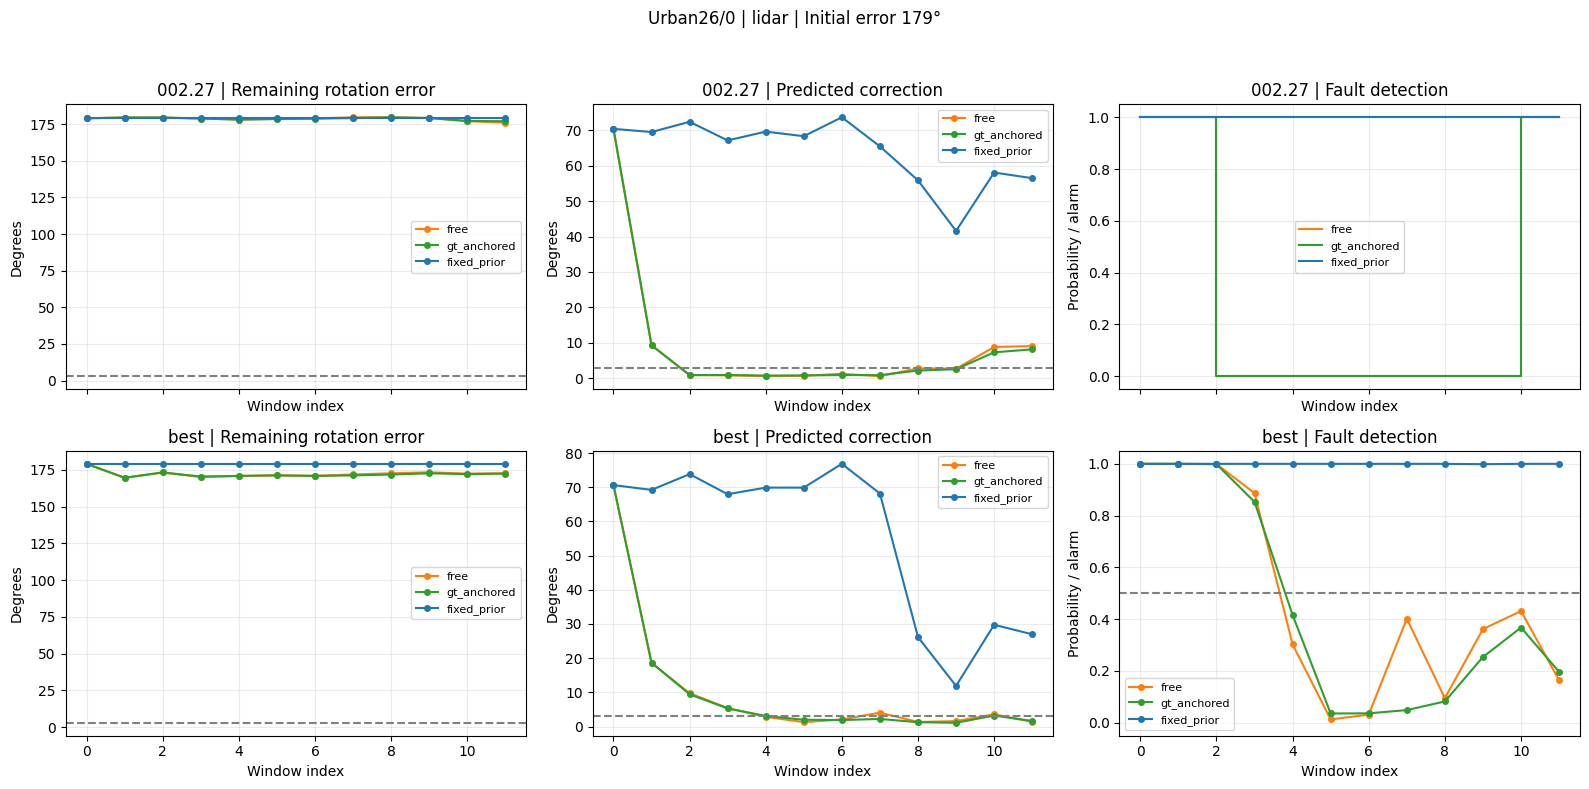

,checkpoint,mode,sensor,n_predictions,n_correct,mean_ctg_deg,mean_correction_deg,mean_probability,alarm_rate,accuracy
0,002.27,fixed_prior,imu,12,12,0.000,0.157,NaN,0.000,1.000
1,002.27,fixed_prior,lidar,12,12,179.000,64.006,NaN,1.000,1.000
2,002.27,fixed_prior,lidar_right,12,12,0.000,0.305,NaN,0.000,1.000
3,002.27,free,imu,12,5,3.480,0.908,NaN,0.083,0.417
4,002.27,free,lidar,12,4,178.670,9.013,NaN,0.333,0.333
5,002.27,free,lidar_right,12,12,0.805,0.545,NaN,0.000,1.000
6,002.27,gt_anchored,imu,12,11,0.000,0.938,NaN,0.083,0.917
7,002.27,gt_anchored,lidar,12,4,178.691,8.771,NaN,0.333,0.333
8,002.27,gt_anchored,lidar_right,12,12,0.000,0.516,NaN,0.000,1.000
9,best,fixed_prior,imu,12,12,0.000,0.580,0.034,0.000,1.000


In [35]:
# %% A4. Fixed-prior experiment: isolate motion-dependent fault detection

@torch.inference_mode()
def collect_fixed_prior_experiment():
    windows = []

    for idx in indices:
        raw = window_batch_to(collate_windows([app_dataset[int(idx)]]), DEVICE, dtype=MODEL_DTYPE)
        windows.append(fixed_seeded_physical(raw, seed))

    truth = windows[0].current_calibration

    # Reproduce exactly the same perturbation as in A3.
    old_settings = ROLLOUT_ANGLES_DEG, ROLLOUT_TIME_FAULT_MS

    try:
        globals()['ROLLOUT_ANGLES_DEG'] = (ANCHOR_ANGLE_DEG,)
        globals()['ROLLOUT_TIME_FAULT_MS'] = ()

        cases = rollout_cases(np.random.default_rng(seed + 51))
        case = next(c for c in cases if c['initial_sensor'] == ANCHOR_SENSOR)
    finally:
        globals()['ROLLOUT_ANGLES_DEG'], globals()['ROLLOUT_TIME_FAULT_MS'] = old_settings

    # Construct the initial calibration once and never update it.
    states = faulted_window_from_cases(windows[0], [case]).current_calibration

    rows = []
    probe = make_initial_model()

    try:
        for label in ('002.27', 'best'):
            if label == '002.27':
                probe.load_state_dict(initial_state, strict=True)
            else:
                load_joint_checkpoint(APP_ROLLOUT_CHECKPOINT, probe)

            probe.eval()

            for step, physical in enumerate(windows):

                for key in CALIBRATION_KEYS:
                    torch.testing.assert_close(physical.current_calibration[key].transform, truth[key].transform)
                    torch.testing.assert_close(physical.current_calibration[key].time_offset, truth[key].time_offset)

                window = WindowBatch(
                    streams=dict(physical.streams),
                    current_calibration=states,
                    metadata=dict(physical.metadata),
                    targets=None,
                    dataset_indices=None,
                )

                out = probe(tokenize_window(window))
                probabilities = out.logits.sigmoid()

                assert tuple(out.calibration_keys) == tuple(CALIBRATION_KEYS)

                for j, key in enumerate(CALIBRATION_KEYS):
                    state = states[key]
                    gt = truth[key]
                    pred = out.predictions[key]

                    R = state.transform[:, :3, :3]
                    R_gt = gt.transform[:, :3, :3]

                    dR = pred.delta_rotation
                    dt = pred.delta_tau

                    eye = torch.eye(3, device=dR.device, dtype=dR.dtype).expand_as(dR)

                    ctg = float(distance_so3_deg(R, R_gt).item())
                    correction = float(distance_so3_deg(dR, eye).item())

                    # Hypothetical residual IF the correction were applied.
                    hypothetical_residual = float(distance_so3_deg(dR @ R, R_gt).item())

                    rows.append(dict(
                        checkpoint=label,
                        mode='fixed_prior',
                        step=step,
                        sensor=key,
                        ctg_deg=ctg,
                        predicted_rotation_deg=correction,
                        predicted_tau_ms=float(dt.item() * 1000),
                        hypothetical_residual_deg=hypothetical_residual,
                        prob_rotation=float(probabilities[0, j, 1]) if label == 'best' else np.nan,
                        reg_alarm=int(correction > GT_ROT_TOL_DEG),
                        gt_fault=int(ctg > GT_ROT_TOL_DEG),
                    ))

                # IMPORTANT: no calibration updates here.

            clear_cuda()

    finally:
        del probe, windows
        clear_cuda()

    return pd.DataFrame(rows)


fixed_prior_df = collect_fixed_prior_experiment()

# Verify that the actual calibration errors remain unchanged.
for sensor in CALIBRATION_KEYS:
    expected = ANCHOR_ANGLE_DEG if sensor == ANCHOR_SENSOR else 0.
    actual = fixed_prior_df.loc[fixed_prior_df.sensor == sensor, 'ctg_deg'].to_numpy()

    np.testing.assert_allclose(actual, expected, atol=0.01, rtol=0.)

fixed_prior_df['cls_alarm'] = fixed_prior_df.prob_rotation >= APP_ROLLOUT_CLASSIFIER_THRESHOLD

fixed_prior_df['alarm'] = np.where(
    fixed_prior_df.checkpoint == '002.27',
    fixed_prior_df.reg_alarm,
    fixed_prior_df.cls_alarm,
).astype(bool)

fixed_prior_df['correct'] = fixed_prior_df.alarm == fixed_prior_df.gt_fault

# -------------------------------------------------------------------------
# Compare free, anchored and fixed-prior experiments
# -------------------------------------------------------------------------

fixed_comparison_df = pd.concat(
    [anchor_df, fixed_prior_df],
    ignore_index=True,
)

colors = {
    'free': 'tab:orange',
    'gt_anchored': 'tab:green',
    'fixed_prior': 'tab:blue',
}

modes = ('free', 'gt_anchored', 'fixed_prior')

fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True)

for row, checkpoint in enumerate(('002.27', 'best')):
    subset = fixed_comparison_df.loc[
        (fixed_comparison_df.checkpoint == checkpoint) &
        (fixed_comparison_df.sensor == ANCHOR_SENSOR)
    ]

    for mode in modes:
        g = subset.loc[subset['mode'] == mode].sort_values('step')
        color = colors[mode]

        axes[row, 0].plot(
            g.step, g.ctg_deg, '-o',
            color=color, label=mode, markersize=4,
        )

        axes[row, 1].plot(
            g.step, g.predicted_rotation_deg, '-o',
            color=color, label=mode, markersize=4,
        )

        if checkpoint == 'best':
            axes[row, 2].plot(
                g.step, g.prob_rotation, '-o',
                color=color, label=mode, markersize=4,
            )
        else:
            axes[row, 2].step(
                g.step, g.reg_alarm,
                where='post', color=color, label=mode,
            )

    axes[row, 0].axhline(GT_ROT_TOL_DEG, color='gray', linestyle='--')
    axes[row, 1].axhline(GT_ROT_TOL_DEG, color='gray', linestyle='--')

    if checkpoint == 'best':
        axes[row, 2].axhline(APP_ROLLOUT_CLASSIFIER_THRESHOLD, color='gray', linestyle='--')

    axes[row, 0].set(
        title=f'{checkpoint} | Remaining rotation error',
        ylabel='Degrees',
    )

    axes[row, 1].set(
        title=f'{checkpoint} | Predicted correction',
        ylabel='Degrees',
    )

    axes[row, 2].set(
        title=f'{checkpoint} | Fault detection',
        ylabel='Probability / alarm',
        ylim=(-0.05, 1.05),
    )

    for ax in axes[row]:
        ax.set_xlabel('Window index')
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)

fig.suptitle(
    f'{sequence}/{example.start_index} | {ANCHOR_SENSOR} | '
    f'Initial error {ANCHOR_ANGLE_DEG:g}°'
)

fig.tight_layout(rect=(0, 0, 1, 0.95))

if SAVE_PLOTS:
    fig.savefig(
        APP_ROLLOUT_DIR / f'fixed_prior_{ANCHOR_SENSOR}_{ANCHOR_ANGLE_DEG:g}.png',
        dpi=PLOT_DPI, bbox_inches='tight',
    )

if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)

# -------------------------------------------------------------------------
# Individual-prediction statistics
# -------------------------------------------------------------------------

fixed_summary = fixed_comparison_df.groupby(
    ['checkpoint', 'mode', 'sensor'],
    as_index=False,
).agg(
    n_predictions=('correct', 'size'),
    n_correct=('correct', 'sum'),
    mean_ctg_deg=('ctg_deg', 'mean'),
    mean_correction_deg=('predicted_rotation_deg', 'mean'),
    mean_probability=('prob_rotation', 'mean'),
    alarm_rate=('alarm', 'mean'),
)

fixed_summary['accuracy'] = fixed_summary.n_correct / fixed_summary.n_predictions

display(fixed_summary.round(3))

fixed_prior_df.to_csv(
    APP_ROLLOUT_DIR / f'fixed_prior_{ANCHOR_SENSOR}_{ANCHOR_ANGLE_DEG:g}.csv',
    index=False,
)